> **Scratch notebook: for exploration and further analysis only.**
>
> This notebook is where the team explored the data before building SAPAT. It is kept for transparency and as a starting point for further analysis, not as the source of record.
> The reproducible pipeline is in `scripts/` (run `python scripts/run_pipeline.py`), and the numbers quoted in the pitch come from `outputs/`. Where the two differ, `scripts/` and `outputs/` are authoritative.
>
> **To run it:** start Jupyter from the repository root or from `notebooks/`. It reads `data_raw/` and `data_clean/`. The two raw FIES files (about 145 MB each) are not in the repository; download them into `data_raw/` first (see `data_raw/README.md`). Every other input ships with the repository.
>
> Saved outputs below are from the last full run (October 2026).

# SAPAT: Food Burden and the Price of Protein in Filipino Households
**PJDSC 2026 · Team SiniGANG** · Exploratory data analysis notebook

This notebook builds the evidence base for SAPAT, a person-specific least-cost nutritious diet planner. It follows six parts:

1. Dataset Description
2. Data Cleaning & Preprocessing
3. Research Question & Exploratory Data Analysis
4. Data Mining
5. Statistical Inference
6. Summary, Conclusions and Recommendations *(next step)*

Everything runs from the raw files in the `PJDSC` folder. Put this notebook in that folder and run all cells.

In [2]:
import re, glob, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Paths work whether Jupyter starts in the repository root or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data_raw").exists() else Path.cwd().parent
RAW = ROOT / "data_raw"        # source files as downloaded (see data_raw/README.md)
CLEAN = ROOT / "data_clean"    # outputs of scripts/build_clean_data.py

# One consistent chart style: thin marks, light grid, fixed categorical order
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MUTED = "#b9b8b2"
plt.rcParams.update({
    "figure.figsize": (9, 4.2), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "axes.prop_cycle": plt.cycler(color=PAL),
})

def wavg(x, w):
    m = np.isfinite(x) & np.isfinite(w)
    return np.average(x[m], weights=w[m])

def wquantile(x, w, q):
    # weighted quantile of x
    x, w = np.asarray(x), np.asarray(w)
    o = np.argsort(x); cw = np.cumsum(w[o]) / w.sum()
    return np.interp(q, cw, x[o])

---
# 1. Dataset Description

The study combines one **primary dataset** and three **supporting datasets**:

| Dataset | Publisher | Unit of observation | Role in the study |
|---|---|---|---|
| **Family Income and Expenditure Survey (FIES) 2023**, Volume 2 household summary, public-use file. The 2021 round is used for comparison. | Philippine Statistics Authority (PSA) | One household | **Primary.** Income, food spending and how the food budget is split |
| Retail Prices of Agricultural Commodities (11 OpenSTAT tables) | PSA | One place × commodity (wide by month) | What food costs, Jan 2018 to Sep 2026 |
| Philippine Food Composition Tables (PhilFCT) | DOST-FNRI | One food | Nutrients per 100 g edible portion |
| Official Poverty Statistics 2023, food and poverty thresholds | PSA | One region × year | Benchmark for the minimum cost of a nutritionally adequate diet |

## 1.1 Primary dataset: FIES 2023 (and 2021)

**What it is.** FIES is the PSA's nationwide household survey of income and spending. It is the official source for poverty statistics and income distribution. The public-use *Volume 2 household summary* has one record per sample household. It gives the household's annual income by source, annual spending by major group (including food groups), family size, region, urban/rural classification and survey weights.

**How it was collected.** In 2023 the PSA interviewed about 181,000 sampled households:
- **Sample design.** Two-stage cluster sampling from the 2023 Geo-enabled Master Sample. Barangays or enumeration areas are the primary units and housing units are the secondary units. The 82 provinces, 33 highly urbanized cities and 3 other urban areas form the strata.
- **Visits.** Each household was interviewed twice: in July 2023 about January–June 2023, and in January 2024 about July–December 2023. Interviews used computer-assisted personal interviewing (CAPI).
- **Food measure.** Food is recorded as *consumption*, not cash spending. It includes food produced by the family (valued at farm-gate prices) and food received as gifts (valued at local market prices), whether eaten at home or regularly outside.
- **Weights.** Each record carries a final weight (`RFACT`). It starts from the inverse selection probability, is adjusted for non-response and is calibrated to projected population counts.

**What this means for the insights.**
- **Weights must be used for population figures.** The sample deliberately over-represents some provinces and cities. Any statement about "Filipino households" uses `RFACT` (households) or `RFACT × FSIZE` (persons). Unweighted figures only describe the sample.
- **Recall and valuation error.** Amounts are recalled for six-month periods, and home-produced food is valued at farm-gate prices. Spending of farming and fishing households is therefore understated relative to what the same food would cost at retail.
- **Only household totals.** There is no per-person intake, no ages and no sexes in this file. We can say how a *household's* food budget is split, not who eats what. This is why SAPAT needs PDRI requirements by life stage as a separate input.
- **Groups, not foods.** Spending is grouped (e.g. "bread and cereals", "meat"). We cannot see grams of rice or eggs bought, only pesos per group.
- **Fractional family size.** Family size is the average across the two visits, so some households have values like 2.5.
- **2021 was a pandemic year.** FIES 2021 was collected under COVID-19 restrictions. Changes from 2021 to 2023 mix recovery effects with price effects.

In [3]:
fies23_raw = pd.read_csv(RAW / "fies_2023_vol2_household_summary_694509957977.csv")
fies21_raw = pd.read_csv(RAW / "fies_2021_volume_2_household_summary.csv")
print(f"FIES 2023: {fies23_raw.shape[0]:,} households x {fies23_raw.shape[1]} columns")
print(f"FIES 2021: {fies21_raw.shape[0]:,} households x {fies21_raw.shape[1]} columns")
print("Columns only in 2023:", sorted(set(fies23_raw.columns) - set(fies21_raw.columns)))
print("Columns only in 2021:", sorted(set(fies21_raw.columns) - set(fies23_raw.columns)))
fies23_raw.head(3)

FIES 2023: 163,268 households x 91 columns
FIES 2021: 165,029 households x 88 columns
Columns only in 2023: ['MEM_RFACT', 'OTHER_NON_ALCOHOL', 'PERCAPITA', 'PRPCINC', 'RPCINC_NIR', 'W_REGN_NIR']
Columns only in 2021: ['BWEIGHT', 'PCINC', 'RFACT_POP']


,RDMD_ID,W_REGN,W_PROV,SEQ_NO,RPROV,FSIZE,REG_SAL,SEASON_SAL,WAGES,NETSHARE,CASH_ABROAD,CASH_DOMESTIC,RENTALS_REC,INTEREST,PENSION,DIVIDENDS,OTHER_SOURCE,NET_RECEIPT,REGFT,NET_CFG,...,OTHER_EXPENDITURE,OTHER_DISBURSEMENT,FOOD_ACCOM_SRVC,NFOOD,TOINC,TOTEX,TOTDIS,OTHREC,TOREC,RPSU,RFACT,MEM_RFACT,URB,PERCAPITA,NPCINC,RPCINC,PRPCINC,PPCINC,RPCINC_NIR,W_REGN_NIR
0,1,1,28,1,2800,2.500,119000,0,119000,0,461000,10000,0,0,0,0,0,4760,310.000,0,...,3700,0,0,"67,389.000","607,070.000","228,942.000","228,942.000",0,"607,070.000",2,88.544,229.392,2,"242,828.000",10,10,10,10,10,1
1,2,1,28,2,2800,6.000,154400,0,154400,0,142000,43000,6000,0,0,0,0,2790,"1,790.000",0,...,800,600,0,"165,819.000","411,980.000","363,077.000","363,677.000",0,"411,980.000",2,88.544,550.541,2,"68,663.336",5,5,2,2,5,1
2,3,1,28,3,2800,3.500,683452,0,683452,0,37000,28000,9000,0,0,0,0,940,"41,820.000",0,...,17200,42709,0,"340,193.000","818,212.000","516,477.000","559,186.000",0,"818,212.000",2,88.544,321.149,2,"233,774.859",10,10,10,10,10,1


**Structure.** Each **row is one household**, and each **column is an annual peso amount** or a household attribute. FIES 2023 has **163,268 households × 91 columns**; FIES 2021 has **165,029 × 88**. All columns are numeric, and amounts are annual pesos. The columns fall into the groups below. Only the variables this study uses are described in detail.

In [4]:
groups = {
    "Identifiers & geography": ["RDMD_ID", "SEQ_NO", "W_REGN", "W_PROV", "RPROV", "RPSU", "URB", "W_REGN_NIR"],
    "Household size & weights": ["FSIZE", "RFACT", "MEM_RFACT"],
    "Income by source (annual PHP)": ["WAGES", "REG_SAL", "SEASON_SAL", "NETSHARE", "CASH_ABROAD", "CASH_DOMESTIC", "RENTALS_REC",
        "INTEREST", "PENSION", "DIVIDENDS", "OTHER_SOURCE", "NET_RECEIPT", "REGFT", "NET_CFG", "NET_LPR", "NET_FISH", "NET_FOR",
        "NET_RET", "NET_MFG", "NET_TRANS", "NET_NEC_A8", "NET_NEC_A9", "NET_NEC_A10", "EAINC", "IMPUTED_RENT", "TOINC"],
    "Food consumption (annual PHP)": ["BREAD", "MEAT", "FISH", "MILK", "OIL", "FRUIT", "VEG", "SUGAR", "FOOD_NEC", "FRUIT_VEG",
        "COFFEE", "TEA", "COCOA", "WATER", "SOFTDRINKS", "OTHER_NON_ALCOHOL", "FOOD_HOME", "FOOD_OUTSIDE", "FOOD"],
    "Non-food spending & totals": ["ALCOHOL", "TOBACCO", "CLOTH", "HOUSING_WATER", "HEALTH", "TRANSPORT", "COMMUNICATION",
        "RECREATION", "EDUCATION", "INSURANCE", "MISCELLANEOUS", "DURABLE", "OCCASION", "NFOOD", "TOTEX", "TOTDIS", "TOREC"],
    "Per-capita income & deciles": ["PERCAPITA", "NPCINC", "RPCINC", "PRPCINC", "PPCINC", "RPCINC_NIR"],
}
pd.DataFrame([(g, len([c for c in cols if c in fies23_raw.columns]), ", ".join(c for c in cols if c in fies23_raw.columns))
              for g, cols in groups.items()], columns=["Attribute group", "# columns", "Columns"])

,Attribute group,# columns,Columns
0,Identifiers & geography,8,"RDMD_ID, SEQ_NO, W_REGN, W_PROV, RPROV, RPSU, ..."
1,Household size & weights,3,"FSIZE, RFACT, MEM_RFACT"
2,Income by source (annual PHP),26,"WAGES, REG_SAL, SEASON_SAL, NETSHARE, CASH_ABR..."
3,Food consumption (annual PHP),19,"BREAD, MEAT, FISH, MILK, OIL, FRUIT, VEG, SUGA..."
4,Non-food spending & totals,17,"ALCOHOL, TOBACCO, CLOTH, HOUSING_WATER, HEALTH..."
5,Per-capita income & deciles,6,"PERCAPITA, NPCINC, RPCINC, PRPCINC, PPCINC, RP..."


**Variables used in this study** (2023 names; 2021 uses `PCINC` for per-capita income):

| Variable | Meaning |
|---|---|
| `W_REGN` | Region code (1–17, plus 19 = BARMM in 2023; BARMM is 15 in 2021) |
| `URB` | 1 = urban, 2 = rural |
| `FSIZE` | Family size (average of the two visits) |
| `RFACT` | Household weight |
| `TOINC` | Total annual family income, all sources including imputed rent |
| `PERCAPITA` | `TOINC / FSIZE` |
| `WAGES` | Salaries and wages |
| `CASH_ABROAD` | Cash remittances from abroad |
| `CASH_DOMESTIC` | Cash support from within the country |
| `NET_CFG`, `NET_LPR`, `NET_FISH`, `NET_FOR` | Net income from crop farming, livestock and poultry, fishing, and forestry |
| `EAINC` | Total entrepreneurial income |
| `FOOD` | Total food consumption (`FOOD_HOME` + `FOOD_OUTSIDE`) |
| `FOOD_HOME` | Food consumed at home |
| `FOOD_OUTSIDE` | Food regularly eaten outside the home |
| `BREAD` | Bread and cereals (rice dominates) |
| `MEAT` | Meat |
| `FISH` | Fish and seafood |
| `MILK` | Milk, cheese and eggs |
| `OIL` | Oils and fats |
| `FRUIT` | Fruit |
| `VEG` | Vegetables |
| `SUGAR` | Sugar, jam, honey and confectionery |
| `FOOD_NEC` | Food not elsewhere classified |
| `TOTEX` | Total family expenditure |

## 1.2 Supporting dataset: PSA retail prices of agricultural commodities

**What it is.** Eleven PSA OpenSTAT tables (beans and legumes, cereals, commercial crops, condiments, fish, fruit vegetables, fruits, leafy vegetables, livestock, poultry, root crops). Each gives the **average monthly retail price** of each commodity for the Philippines, every region and every province, January 2018 to the latest month.

**How it was collected.** PSA's Retail Price Survey visits selected markets in NCR, the provinces and Davao and Zamboanga cities two or three times a week. It records prices from about five retailers per commodity per market. These are averaged to monthly figures.

**Implications.**
- Prices come from **public and provincial market centres**, not from sari-sari stores or remote barangays where poorer households often buy in small packs at higher unit prices. Food costs for the poorest households are therefore probably *understated*.
- A region's figure is an **average across markets**, which hides within-region spread.
- Many province and commodity combinations are never surveyed, so the tables are sparse.
- **Prices are per kilogram or per piece *as purchased*.** Nutrients must be adjusted for the inedible part (bones, shells, peels).

**Structure (raw).** The first line is a title. After it, each row is a place × commodity pair, with the place written only on the first of its rows. Then come one column per month and one "Annual" column per year.

In [5]:
price_files = sorted(glob.glob(str(RAW / "psa_openstat_retail_prices" / "*.csv")))
raw_tables = {}
for f in price_files:
    name = Path(f).name.split("-")[0].strip()
    raw_tables[name] = pd.read_csv(f, skiprows=1, encoding="latin1", dtype=str)
pd.DataFrame([(k, v.shape[0], v.shape[1], v["Commodity"].nunique(), v["Geolocation"].notna().sum()) for k, v in raw_tables.items()],
             columns=["Table", "Rows (place x commodity)", "Columns", "Commodities", "Rows with a place name"])

,Table,Rows (place x commodity),Columns,Commodities,Rows with a place name
0,Beans and Legumes,833,119,7,833
1,Cereals,1666,119,14,1666
2,Commercial Crops,238,119,2,238
3,Condiments,833,119,7,833
4,Fish,6783,119,57,6783
5,Fruit Vegetables,1071,119,9,1071
6,Fruits,4284,119,36,4284
7,Leafy Vegetables,1428,119,12,1428
8,Livestock,1547,119,13,1547
9,Poultry,1785,119,15,1785


In [6]:
raw_tables["Cereals"].iloc[12:20, :6]

,Geolocation,Commodity,2018 January,2018 February,2018 March,2018 April
12,Philippines,"WHOLE CORN ON THE COB, WHITE, 1 KG",33.00,34.20,34.63,34.35
13,Philippines,"WHOLE CORN ON THE COB, YELLOW, 1 KG",42.99,42.44,42.17,42.78
14,..NCR - National Capital Region,"RICE, WELL-MILLED, 1 KG",43.80,43.94,44.17,44.19
15,..NCR - National Capital Region,"RICE, REGULAR-MILLED, 1 KG",37.26,37.42,38.03,38.07
16,..NCR - National Capital Region,"RICE, SPECIAL, 1 KG",54.62,54.89,54.96,54.98
17,..NCR - National Capital Region,"CORN GRITS, CORN NATIVE, 1 KG",..,..,..,..
18,..NCR - National Capital Region,"CORN GRITS, LOOSE, 1 KG",..,..,..,..
19,..NCR - National Capital Region,"CORN GRITS, WHITE, #10, 1 KG",..,..,..,..


## 1.3 Supporting datasets: PhilFCT and PSA thresholds

**PhilFCT (DOST-FNRI, Release 1, 2019).** One record per food, giving nutrients per 100 g *edible portion* (EP) and the EP percentage. The team exported one PDF report per food and compiled them into `philfct_mapped.csv`. These are laboratory compositions of a representative sample. Varieties sold in a given market can differ.

**PSA food threshold.** The minimum income a person needs in a year to buy a menu that meets basic energy and nutrient requirements, priced regionally (2018, 2021, 2023). It is the official benchmark for what a nutritionally adequate diet costs. It is read from Tables 1 and 3 of the 2023 Official Poverty Statistics publication.

In [7]:
fct_raw = pd.read_csv(RAW / "philfct_mapped.csv")
print(fct_raw.shape)
fct_raw[["commodity", "match_status", "fct_food_id", "fct_food_name", "ep_pct", "energy_kcal", "protein_g", "iron_mg", "vit_a_rae_ug", "calcium_mg", "notes"]].head(8)

(71, 29)


,commodity,match_status,fct_food_id,fct_food_name,ep_pct,energy_kcal,protein_g,iron_mg,vit_a_rae_ug,calcium_mg,notes
0,Maize (white),proxy,A001,"Corn grits, white",100.000,357.000,8.300,0.400,0.000,11.000,Whole maize grain not exported; corn grits use...
1,Maize (yellow),proxy,A002,"Corn grits, yellow",100.000,350.000,7.700,1.300,5.000,22.000,Whole maize grain not exported; corn grits use...
2,Maize flour (white),matched,A001,"Corn grits, white",100.000,357.000,8.300,0.400,0.000,11.000,NaN
3,Maize flour (yellow),matched,A002,"Corn grits, yellow",100.000,350.000,7.700,1.300,5.000,22.000,NaN
4,Potatoes (Irish),matched,B007,Potato,85.000,78.000,2.400,1.100,0.000,36.000,NaN
5,"Rice (milled, superior)",matched,A019,"Rice, well-milled",100.000,356.000,7.400,1.000,0.000,27.000,NaN
6,Rice (premium),matched,A019,"Rice, well-milled",100.000,356.000,7.400,1.000,0.000,27.000,NaN
7,"Rice (regular, milled)",WRONG ENTRY,A012,"Rice, milled, glutinous",100.000,355.000,6.900,1.100,0.000,26.000,"Report is A012 glutinous rice (malagkit), not ..."


---
# 2. Data Cleaning & Preprocessing

Only the variables used in the study are cleaned. Each step checks for a problem, shows what it found and says what was done.

## 2.1 FIES

### Step 1: Keep the variables used and align the two years

In [8]:
INCOME_SRC = ["WAGES", "CASH_ABROAD", "CASH_DOMESTIC", "NET_CFG", "NET_LPR", "NET_FISH", "NET_FOR", "EAINC", "IMPUTED_RENT"]
FOOD_GRP = ["BREAD", "MEAT", "FISH", "MILK", "OIL", "FRUIT", "VEG", "SUGAR", "FOOD_NEC"]
KEEP = ["W_REGN", "URB", "FSIZE", "RFACT", "TOINC", "TOTEX", "FOOD", "FOOD_HOME", "FOOD_OUTSIDE"] + FOOD_GRP + INCOME_SRC

f23 = fies23_raw[KEEP + ["PERCAPITA"]].rename(columns={"PERCAPITA": "PCINC"}).assign(year=2023)
f21 = fies21_raw[KEEP + ["PCINC"]].assign(year=2021)
fies = pd.concat([f21, f23], ignore_index=True)
fies.columns = fies.columns.str.lower()
print(fies.shape)
fies.dtypes.value_counts()

(328297, 29)


float64    17
int64      12
Name: count, dtype: int64

### Step 2: Data types, missing values and duplicates
All kept columns are numeric (`int64` or `float64`), which is correct for peso amounts and codes. Region and urbanity are codes stored as integers and are recoded in Step 3. Each household appears once per year (`RDMD_ID` and `SEQ_NO` are unique within each file).

In [9]:
print("Missing values per column (both years):", int(fies.isna().sum().sum()))
for nm, raw in [("2021", fies21_raw), ("2023", fies23_raw)]:
    print(f"{nm}: duplicated RDMD_ID = {raw.RDMD_ID.duplicated().sum()}, duplicated SEQ_NO = {raw.SEQ_NO.duplicated().sum()}, fully duplicated rows = {raw.duplicated().sum()}")

Missing values per column (both years): 0
2021: duplicated RDMD_ID = 0, duplicated SEQ_NO = 0, fully duplicated rows = 0
2023: duplicated RDMD_ID = 0, duplicated SEQ_NO = 0, fully duplicated rows = 0


### Step 3: Recode categorical codes
- **One region under two codes.** BARMM is code `15` in 2021 (as ARMM) and code `19` in 2023. Both become `BARMM`.
- **Region names.** Codes are mapped to the region names used by PSA, so FIES joins to the price and threshold tables.
- **Urbanity.** `URB` 1/2 becomes the labels Urban and Rural.

In [10]:
REGION = {13: "NCR", 14: "CAR", 1: "I Ilocos", 2: "II Cagayan Valley", 3: "III Central Luzon", 4: "IV-A CALABARZON",
          17: "MIMAROPA", 5: "V Bicol", 6: "VI Western Visayas", 7: "VII Central Visayas", 8: "VIII Eastern Visayas",
          9: "IX Zamboanga Pen.", 10: "X Northern Mindanao", 11: "XI Davao", 12: "XII SOCCSKSARGEN", 16: "XIII Caraga",
          15: "BARMM", 19: "BARMM"}
REGION_KEY = {13: "NCR", 14: "CAR", 1: "R01", 2: "R02", 3: "R03", 4: "R4A", 17: "R4B", 5: "R05", 6: "R06", 7: "R07", 8: "R08",
              9: "R09", 10: "R10", 11: "R11", 12: "R12", 16: "R13", 15: "BARMM", 19: "BARMM"}
REGION_ORDER = list(dict.fromkeys(REGION.values()))
print(pd.crosstab(fies.w_regn, fies.year).loc[[15, 19]])
fies["region"] = pd.Categorical(fies.w_regn.map(REGION), categories=REGION_ORDER)
fies["region_key"] = fies.w_regn.map(REGION_KEY)
fies["area"] = fies.urb.map({1: "Urban", 2: "Rural"})
assert fies.region.notna().all() and fies.area.notna().all()
fies.groupby("year").region.nunique()

year    2021   2023
w_regn             
15      8212      0
19         0  10465


year
2021    17
2023    17
Name: region, dtype: int64

### Step 4: Impossible or inconsistent values
We check for:
- **negative incomes**: enterprise net income can be a loss;
- **households with no food at home**;
- **food consumption above total income**: possible when households draw on savings or borrow, or when income is under-reported;
- **fractional family sizes**.

We also confirm that the parts add up to their totals.

In [11]:
checks = {}
for y, d in fies.groupby("year"):
    checks[y] = {
        "negative farm/fishing net income": int((d[["net_cfg", "net_lpr", "net_fish", "net_for"]] < 0).any(axis=1).sum()),
        "FOOD_HOME == 0": int((d.food_home == 0).sum()),
        "FOOD > TOINC (food exceeds income)": int((d.food > d.toinc).sum()),
        "fractional FSIZE": int((d.fsize % 1 != 0).sum()),
        "max |FOOD - (FOOD_HOME + FOOD_OUTSIDE)|": float((d.food - d.food_home - d.food_outside).abs().max()),
    }
pd.DataFrame(checks)

,2021,2023
negative farm/fishing net income,21.000,32.000
FOOD_HOME == 0,2.000,1.000
FOOD > TOINC (food exceeds income),224.000,68.000
fractional FSIZE,"39,351.000","40,229.000"
max |FOOD - (FOOD_HOME + FOOD_OUTSIDE)|,0.000,0.000


**Decisions.**
- **Negative farm or fishing income** affects only a few dozen households. These are business losses, so they are clipped to 0 when computing *income shares*. Total income is left unchanged.
- **Zero food at home** affects three households (two in 2021, one in 2023). They are dropped, because the food-composition shares would divide by 0.
- **Food above income** is real dissaving (224 households in 2021 and 68 in 2023, under 0.2%), not a coding error, so these households are kept. For the burden measure we also compute food as a share of *total expenditure*, which cannot exceed 1. The income-based share is truncated at 1 for plots and mining.
- **Fractional family size** is kept as is. It is PSA's average of the two visits and is the denominator PSA itself uses for per-capita income.

### Step 5: Feature engineering
New variables used in the analysis:

| Feature | Definition |
|---|---|
| `food_share_inc` | `FOOD / TOINC` (Engel ratio), truncated at 1 |
| `food_share_exp` | `FOOD / TOTEX` |
| `food_pc_day` | `FOOD / FSIZE / 365`, in pesos per person per day |
| `sh_cereal`, `sh_meat`, `sh_fish`, `sh_milk_eggs`, `sh_veg_fruit`, `sh_oil_sugar`, `sh_other` | Each group's share of `FOOD_HOME` |
| `sh_animal` | Meat + fish + milk/eggs |
| `sh_outside` | `FOOD_OUTSIDE / FOOD` |
| `inc_wages`, `inc_abroad`, `inc_domestic`, `inc_agri`, `inc_enterprise`, `inc_other` | Each source's share of income |
| `person_w` | `RFACT × FSIZE`, the person weight |
| `decile` | Per-capita income decile **weighted by persons**: each decile holds 10% of Filipinos, not 10% of households, matching how PSA reports income groups of the population |

In [12]:
f = fies
f["food_share_inc_raw"] = f.food / f.toinc
f["food_share_inc"] = f.food_share_inc_raw.clip(upper=1)
f["food_share_exp"] = f.food / f.totex
f["food_pc_day"] = f.food / f.fsize / 365
f["pcinc_day"] = f.pcinc / 365
fh = f.food_home.replace(0, np.nan)
f["sh_cereal"] = f.bread / fh
f["sh_meat"] = f.meat / fh
f["sh_fish"] = f.fish / fh
f["sh_milk_eggs"] = f.milk / fh
f["sh_veg_fruit"] = (f.veg + f.fruit) / fh
f["sh_oil_sugar"] = (f.oil + f.sugar) / fh
f["sh_other"] = 1 - f[["sh_cereal", "sh_meat", "sh_fish", "sh_milk_eggs", "sh_veg_fruit", "sh_oil_sugar"]].sum(axis=1)
f["sh_animal"] = f.sh_meat + f.sh_fish + f.sh_milk_eggs
f["sh_outside"] = f.food_outside / f.food

agri = f[["net_cfg", "net_lpr", "net_fish", "net_for"]].clip(lower=0).sum(axis=1)
f["inc_wages"] = f.wages / f.toinc
f["inc_abroad"] = f.cash_abroad / f.toinc
f["inc_domestic"] = f.cash_domestic / f.toinc
f["inc_agri"] = agri / f.toinc
f["inc_enterprise"] = (f.eainc - agri).clip(lower=0) / f.toinc
f["inc_other"] = (1 - f[["inc_wages", "inc_abroad", "inc_domestic", "inc_agri", "inc_enterprise"]].sum(axis=1)).clip(lower=0)
f["person_w"] = f.rfact * f.fsize

def pop_decile(d):
    d = d.sort_values("pcinc")
    cw = d.person_w.cumsum() / d.person_w.sum()
    return pd.Series(np.minimum(np.ceil(cw * 10), 10).astype(int), index=d.index)
f["decile"] = f.groupby("year", group_keys=False)[["pcinc", "person_w"]].apply(pop_decile)
print(f.groupby(["year", "decile"]).person_w.sum().div(f.groupby("year").person_w.sum(), level=0).unstack().round(3))

decile    1     2     3     4     5     6     7     8     9     10
year                                                              
2021   0.100 0.100 0.100 0.100 0.100 0.100 0.100 0.100 0.100 0.100
2023   0.100 0.100 0.100 0.100 0.100 0.100 0.100 0.100 0.100 0.100


### Step 6: Outliers
Income is strongly right-skewed. The richest households earn hundreds of times the median, as expected for income data. We do **not delete** them because they are genuine households. Instead:
- per-capita income is analysed on a **log10 scale**;
- ratios (shares) are bounded between 0 and 1 by construction;
- for plots and clustering, peso-per-day variables are **winsorized at the 1st and 99th percentiles** within each year.

In [13]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return ((s < q1 - k) | (s > q3 + k)).mean()
d23 = f[f.year == 2023]
pd.DataFrame({
    "skewness": d23[["pcinc", "food_pc_day", "food_share_inc", "sh_cereal"]].skew(),
    "share beyond 1.5×IQR": [iqr_outliers(d23[c]) for c in ["pcinc", "food_pc_day", "food_share_inc", "sh_cereal"]],
    "max / median": d23[["pcinc", "food_pc_day", "food_share_inc", "sh_cereal"]].max() / d23[["pcinc", "food_pc_day", "food_share_inc", "sh_cereal"]].median(),
})

,skewness,share beyond 1.5×IQR,max / median
pcinc,114.779,0.074,629.233
food_pc_day,2.489,0.048,14.951
food_share_inc,0.356,0.005,2.701
sh_cereal,0.583,0.012,3.230


findfont: Failed to find font weight semibold, now using 700.


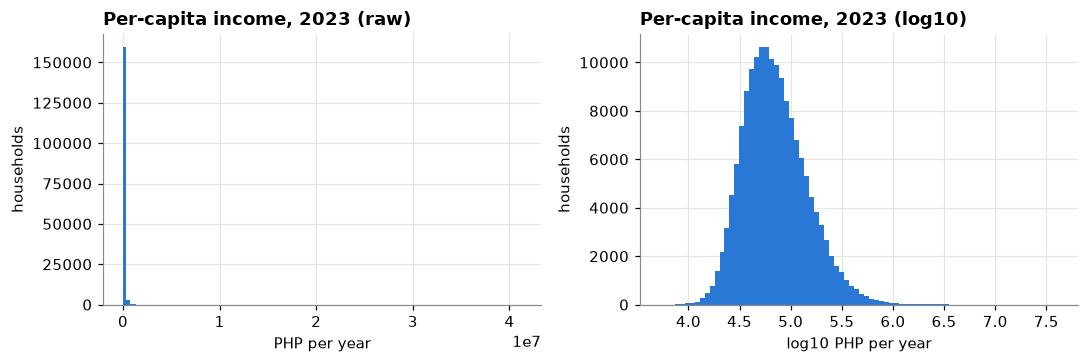

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].hist(d23.pcinc, bins=120, color=PAL[0]); ax[0].set_title("Per-capita income, 2023 (raw)"); ax[0].set_xlabel("PHP per year")
ax[1].hist(np.log10(d23.pcinc), bins=80, color=PAL[0]); ax[1].set_title("Per-capita income, 2023 (log10)"); ax[1].set_xlabel("log10 PHP per year")
for a in ax: a.set_ylabel("households")
plt.tight_layout()

In [15]:
f["log_pcinc"] = np.log10(f.pcinc)
for c in ["food_pc_day", "pcinc_day"]:
    lo = f.groupby("year")[c].transform(lambda s: s.quantile(.01))
    hi = f.groupby("year")[c].transform(lambda s: s.quantile(.99))
    f[c + "_w"] = f[c].clip(lo, hi)
f = f[f.food_home > 0].copy()       # drops the 3 households with no food at home
fies = f
print(fies.shape)
fies.groupby("year")[["food_share_inc", "food_share_exp", "food_pc_day", "sh_cereal", "sh_animal", "inc_agri", "inc_abroad"]].median()

(328294, 57)


,food_share_inc,food_share_exp,food_pc_day,sh_cereal,sh_animal,inc_agri,inc_abroad
year,,,,,,,
2021,0.382,0.494,57.649,0.305,0.389,0.000,0.000
2023,0.370,0.476,65.924,0.310,0.388,0.000,0.000


## 2.2 PSA retail prices

### Step 1: Fix the layout, the place names and the missing-value markers
Problems found in the raw tables:
- **Place name written once.** The place appears only on its first row, so it is forward-filled.
- **The country is written two ways.** It is `PHILIPPINES` in most tables but `Philippines` in Cereals. Both become `PH`.
- **Hierarchy shown with dots.** Regions start with `..` and provinces with `....`. These dots give each row a geographic level.
- **Missing prices are text.** They are stored as `..` (and `.`), not as empty cells, so every column was read as text.
- **Mixed rows.** Monthly columns sit next to yearly `Annual` averages.

In [16]:
geo_spellings = sorted({g for t in raw_tables.values() for g in t.Geolocation.dropna().unique() if g.strip(".").upper() == "PHILIPPINES"})
tokens = pd.Series([v for t in raw_tables.values() for v in t.iloc[:, 2:].stack().values if not re.fullmatch(r"[\d,]*\.?\d+", str(v))]).value_counts()
print("Spellings of the country row:", geo_spellings)
print("Non-numeric tokens in price cells:\n", tokens.to_string())

Spellings of the country row: ['PHILIPPINES', 'Philippines']
Non-numeric tokens in price cells:
 ..    1872733
.       93772


In [17]:
long = []
for name, t in raw_tables.items():
    t = t.copy(); t["Geolocation"] = t["Geolocation"].ffill()
    mcols = [c for c in t.columns if re.fullmatch(r"\d{4} [A-Z][a-z]+", c) and not c.endswith("Annual")]   # monthly columns only
    l = t.melt(id_vars=["Geolocation", "Commodity"], value_vars=mcols, var_name="period", value_name="raw")
    l["table"] = name; long.append(l)
prices = pd.concat(long, ignore_index=True)
n_cells = len(prices)
prices["price"] = pd.to_numeric(prices.raw.str.replace(",", ""), errors="coerce")   # '..' and '.' -> NaN
prices["date"] = pd.to_datetime(prices.period, format="%Y %B")
g = prices.Geolocation
prices["level"] = np.select([g.str.strip(".").str.upper() == "PHILIPPINES", g.str.startswith("...."), g.str.startswith("..")],
                            ["national", "province", "region"], "other")
prices["place"] = np.where(prices.level == "national", "PH", g.str.lstrip("."))
prices = prices.rename(columns={"Commodity": "commodity"})
print(f"{n_cells:,} cells -> {prices.price.notna().sum():,} with a price ({prices.price.notna().mean():.0%})")
print(prices.level.value_counts().to_dict())

2,531,844 cells -> 721,299 with a price (28%)
{'province': 2127600, 'region': 382968, 'national': 21276}


### Step 2: Missing data, duplicates, data types and outliers
- **Missing prices.** About 72% of cells are empty because many province × commodity pairs are never surveyed. We drop empty cells and do **not** impute. Imputing would invent prices that were never observed. Coverage is reported instead (EDA Q5).
- **Duplicates.** We check for repeated place × commodity × month keys.
- **Data types.** `price` is now `float64` and `date` is `datetime64`.
- **Outliers.** A price more than 4 robust standard deviations from its own 13-month rolling median (on a log scale) is *flagged*. It is kept, because sudden spikes like the 2023 onion crisis are real. Nothing about this rule is tuned to the data.

In [18]:
prices = prices.dropna(subset=["price"])
print("duplicate place x commodity x month keys:", prices.duplicated(["Geolocation", "commodity", "date"]).sum())
prices = prices.sort_values(["Geolocation", "commodity", "date"])
lp = np.log(prices.price)
grp = [prices.Geolocation, prices.commodity]
med = lp.groupby(grp).transform(lambda s: s.rolling(13, center=True, min_periods=5).median())
mad = (lp - med).abs().groupby(grp).transform(lambda s: s.rolling(13, center=True, min_periods=5).median())
prices["outlier"] = (lp - med).abs() > 4 * 1.4826 * mad.clip(lower=0.02)
print(f"flagged outliers: {prices.outlier.sum():,} ({prices.outlier.mean():.2%}), kept")
prices[["table", "place", "level", "commodity", "date", "price", "outlier"]].dtypes

duplicate place x commodity x month keys: 0
flagged outliers: 7,214 (1.00%), kept


table                   str
place                   str
level                   str
commodity               str
date         datetime64[us]
price               float64
outlier                bool
dtype: object

### Step 3: Link prices to nutrients
Each PSA commodity is linked to one PhilFCT entry through a hand-built crosswalk. Proxies are labelled. Reviewing `philfct_mapped.csv` turned up **three wrong matches**, which were corrected:

| Commodity | Wrong entry in mapping file | Correction |
|---|---|---|
| Regular-milled rice | A012 *glutinous* rice | A019 well-milled rice (proxy) |
| Crab | G036 crab *fat* (alige) | G040 mud crab without fat, from the team's newer PDF export |
| Fresh dilis | G150 *dried* anchovy, with 69 g protein per 100 g (about 4× fresh) | Excluded |

Bone-in pork, bone-in beef and shelled peanuts, which were missing, come from the newer PDF exports.

**Unit conversions:**
- Eggs priced per piece are converted at 55 g per medium chicken egg and 70 g per duck egg.
- Coconuts priced per piece use 1,000 g. This weight was calibrated by comparing PSA per-piece prices with WFP per-kg prices for the same region and month.

The crosswalk and the parsed PDF nutrients come from `sapat_pipeline/data_clean`.

The nutrient obtained per peso for food *j* in month *t* is:

$$n_{jt} = \frac{a_j \times EP_j / 100}{p_{jt}}$$

where $a_j$ is the nutrient per 100 g edible portion, $EP_j$ is the edible-portion percentage and $p_{jt}$ is the price of 100 g as purchased. Without the edible-portion term, bony fish and bone-in meat would look like better value than they are.

In [19]:
xw = pd.read_csv(CLEAN / "commodity_crosswalk.csv")
fct = pd.read_csv(CLEAN / "philfct_nutrients.csv")
print(xw.match_type.value_counts().to_dict(), "| foods:", len(xw), "| PhilFCT entries:", len(fct))
xw[xw.match_type == "proxy"][["psa_commodity", "fct_food_id", "note"]]

{'matched': 52, 'proxy': 12} | foods: 64 | PhilFCT entries: 61


,psa_commodity,fct_food_id,note
0,"RICE, REGULAR-MILLED, 1 KG",A019,PhilFCT has no regular-milled entry; well-mill...
2,"RICE, SPECIAL, 1 KG",A019,Special rice priced; well-milled composition used
5,"WHOLE CORN GRAIN, YELLOW, 1 KG",A002,Whole grain priced; yellow corn grits composit...
7,"SWEET POTATO (CAMOTE), 1 KG",B009,Purple kamote composition used for generic camote
13,"FRESH BEEF, MEAT WITH BONES, 1 KG",F035,Beef shank (EP 89%) as bone-in beef
14,"FRESH PORK, KASIM, 1 KG",F157,Boston butt lean (paypay) for kasim (shoulder)
16,"FRESH PORK, MEAT WITH BONES, 1 KG",F182,Pork spare rib (EP 46%) as bone-in pork
26,"FRESH FISH, ALOY/TULINGAN, MEDIUM, 1 KG",G146,Frigate tuna composition
27,"FRESH FISH, SHORT MACKEREL (HASA HASA/KABAYAS/...",G073,Indian mackerel (alumahan) composition for sho...
30,"FRESH FISH, CAESIO, DALAGANG-BUKID, MEDIUM, 1 KG",G010,Goldband fusilier composition


In [20]:
sra = pd.read_csv(RAW / "sra_sugar_retail_mm_monthly.csv", parse_dates=["date"])
sra = sra[sra.outlet == "wet"]
sugar = pd.concat([sra.assign(commodity="SRA REFINED SUGAR, 1 KG", price=sra.refined_avg),
                   sra.assign(commodity="SRA RAW SUGAR, 1 KG", price=sra.raw_avg)])[["date", "commodity", "price"]]
nat = pd.concat([prices[prices.level == "national"][["date", "commodity", "price", "outlier"]], sugar.assign(outlier=False)])
reg = prices[prices.level == "region"][["place", "date", "commodity", "price", "outlier"]]

def add_nutrients(d):
    d = d.merge(xw[["psa_commodity", "fct_food_id", "food_group", "grams_per_unit"]], left_on="commodity", right_on="psa_commodity")
    d = d.merge(fct[["fct_food_id", "fct_food_name", "ep_pct", "energy_kcal", "protein_g", "iron_mg", "vit_a_rae_ug", "calcium_mg"]], on="fct_food_id")
    d["price_100g"] = d.price / (d.grams_per_unit / 100)
    for k in ["energy_kcal", "protein_g", "iron_mg", "vit_a_rae_ug", "calcium_mg"]:
        d[k + "_per_peso"] = d[k] * d.ep_pct / 100 / d.price_100g
    d["php_per_10g_protein"] = 10 / d.protein_g_per_peso
    return d
nat_n = add_nutrients(nat)
reg_n = add_nutrients(reg)
print("national panel:", nat_n.shape, "| regional panel:", reg_n.shape, "| foods:", nat_n.commodity.nunique())
nat_n[nat_n.date == nat_n.date.max()][["commodity", "price", "grams_per_unit", "ep_pct", "protein_g", "php_per_10g_protein"]].sort_values("php_per_10g_protein").head(8)

national panel: (6668, 22) | regional panel: (86375, 23) | foods: 64


,commodity,price,grams_per_unit,ep_pct,protein_g,php_per_10g_protein
5459,"RAW PEANUT, WITHOUT SHELL, 1 KG",123.190,"1,000.000",100.000,25.800,4.775
6089,"CORN GRITS, YELLOW, 1 KG",39.580,"1,000.000",100.000,7.700,5.140
4829,"MONGGO, GREEN, 1 KG",124.550,"1,000.000",100.000,23.200,5.369
5984,"CORN GRITS, WHITE, 1 KG",49.680,"1,000.000",100.000,8.300,5.986
6509,"WHOLE CORN GRAIN, YELLOW, 1 KG",47.710,"1,000.000",100.000,7.700,6.196
6194,"RICE, REGULAR-MILLED, 1 KG",50.100,"1,000.000",100.000,7.400,6.770
6404,"RICE, WELL-MILLED, 1 KG",55.680,"1,000.000",100.000,7.400,7.524
6299,"RICE, SPECIAL, 1 KG",63.720,"1,000.000",100.000,7.400,8.611


## 2.3 Thresholds and the cleaned analysis tables
The regional food thresholds were read from the PSA PDF by `sapat_pipeline/scripts/build_clean_data.py`. They are checked against the published national 2023 values: a food threshold of PHP 22,994 and a poverty incidence of 10.9% among families. They are then joined to every household by region and year.

In [21]:
th = pd.read_csv(CLEAN / "psa_thresholds_2018_2021_2023.csv").set_index("region_key")
assert th.loc["PH", "food_threshold_2023"] == 22994 and th.loc["PH", "poverty_incidence_fam_pct_2023"] == 10.9
ft_long = pd.concat([th[[f"food_threshold_{y}", f"poverty_incidence_fam_pct_{y}"]].set_axis(["food_threshold", "poverty_inc"], axis=1).assign(year=y)
                     for y in (2021, 2023)]).reset_index()
fies = fies.merge(ft_long, on=["region_key", "year"], how="left")
fies["ft_day"] = fies.food_threshold / 365
fies["below_ft"] = (fies.food / fies.fsize) < fies.food_threshold
print("households without a threshold:", fies.food_threshold.isna().sum())
print({"fies": fies.shape, "national prices": nat_n.shape, "regional prices": reg_n.shape})

households without a threshold: 0
{'fies': (328294, 61), 'national prices': (6668, 22), 'regional prices': (86375, 23)}


---
# 3. Research Question & Exploratory Data Analysis

## 3.1 Starting question
We started from the premise of SAPAT: *"Do Filipino households, especially poor ones, eat poorly because they don't know better, or because nutritious food costs more than their budget allows?"*

That is too broad to answer directly, so we asked five EDA questions. Each answer narrowed the next question.

| # | EDA question | Data |
|---|---|---|
| Q1 | How does the share of income spent on food change with income, and how does the *composition* of the food budget shift? | FIES 2023 (vs 2021) |
| Q2 | Is household food spending enough to buy the PSA's minimum nutritious diet? Who falls short? | FIES + food thresholds |
| Q3 | How do food burden and diet composition differ across regions and between urban and rural households? | FIES + poverty incidence |
| Q4 | Which household characteristics (income sources, family size) go with a heavy food burden and a cereal-heavy budget? | FIES |
| Q5 | How have food prices moved since 2018, and how much protein does a peso buy from each food? | PSA prices + PhilFCT |

Population figures use the survey weights. Distributions such as boxplots show the unweighted sample.

## EDA Q1: How do food burden and the food budget change with income?

In [22]:
def decile_table(d):
    w = d.rfact
    return pd.Series({
        "pc income (PHP/yr, median)": wquantile(d.pcinc, d.person_w, .5),
        "food share of income (agg.)": (d.food * w).sum() / (d.toinc * w).sum(),
        "food share of income (median)": wquantile(d.food_share_inc, w, .5),
        "food share IQR": wquantile(d.food_share_inc, w, .75) - wquantile(d.food_share_inc, w, .25),
        "food PHP/person/day": (d.food * w).sum() / (d.fsize * w).sum() / 365,
        "cereals % of home food": (d.bread * w).sum() / (d.food_home * w).sum(),
        "meat %": (d.meat * w).sum() / (d.food_home * w).sum(),
        "fish %": (d.fish * w).sum() / (d.food_home * w).sum(),
        "milk & eggs %": (d.milk * w).sum() / (d.food_home * w).sum(),
        "veg & fruit %": ((d.veg + d.fruit) * w).sum() / (d.food_home * w).sum(),
        "eating out % of food": (d.food_outside * w).sum() / (d.food * w).sum(),
    })
q1 = fies[fies.year == 2023].groupby("decile").apply(decile_table)
q1

,"pc income (PHP/yr, median)",food share of income (agg.),food share of income (median),food share IQR,food PHP/person/day,cereals % of home food,meat %,fish %,milk & eggs %,veg & fruit %,eating out % of food
decile,,,,,,,,,,,
1,"23,604.359",0.528,0.533,0.166,32.954,0.442,0.106,0.146,0.056,0.110,0.048
2,"32,920.000",0.473,0.476,0.163,42.578,0.390,0.133,0.153,0.060,0.112,0.064
3,"40,430.000",0.442,0.445,0.158,49.026,0.361,0.149,0.155,0.062,0.116,0.077
4,"48,233.332",0.416,0.422,0.151,55.085,0.334,0.166,0.156,0.065,0.118,0.096
5,"56,939.773",0.391,0.393,0.145,61.071,0.316,0.180,0.155,0.065,0.120,0.109
6,"67,585.063",0.368,0.370,0.144,68.209,0.296,0.192,0.156,0.067,0.123,0.124
7,"80,913.658",0.342,0.344,0.139,76.143,0.277,0.204,0.158,0.068,0.127,0.137
8,"100,186.381",0.312,0.313,0.130,86.027,0.263,0.211,0.157,0.070,0.130,0.152
9,"132,500.000",0.271,0.274,0.122,99.679,0.246,0.218,0.155,0.074,0.136,0.170


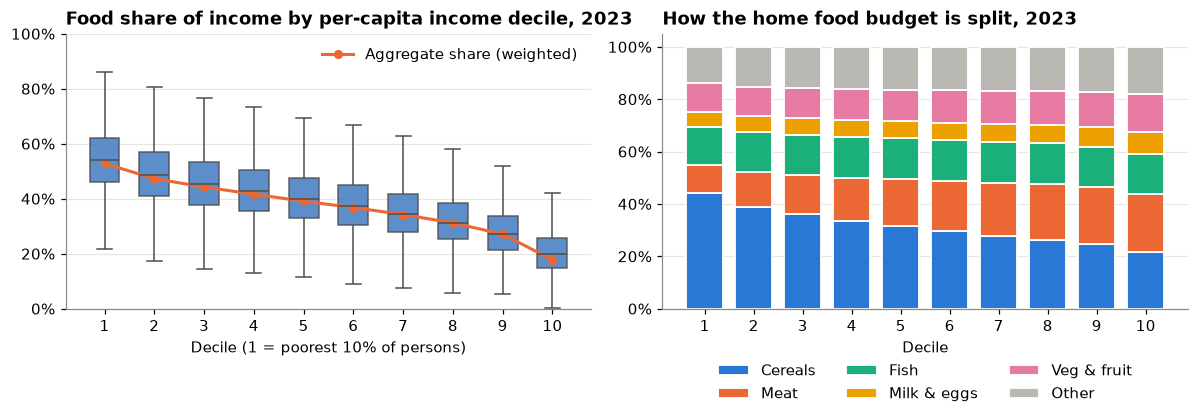

In [23]:
d = fies[fies.year == 2023]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=d, x="decile", y="food_share_inc", ax=ax[0], color=PAL[0], fliersize=0, width=.6, linewidth=1, boxprops=dict(alpha=.85))
ax[0].plot(range(10), q1["food share of income (agg.)"].values, "o-", color=PAL[1], lw=2, ms=5, label="Aggregate share (weighted)")
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[0].set_ylim(0, 1)
ax[0].set_title("Food share of income by per-capita income decile, 2023"); ax[0].set_xlabel("Decile (1 = poorest 10% of persons)"); ax[0].set_ylabel("")
ax[0].legend(loc="upper right")

comp = q1[["cereals % of home food", "meat %", "fish %", "milk & eggs %", "veg & fruit %"]]
comp = comp.assign(other=1 - comp.sum(axis=1))
bottom = np.zeros(10)
labels = ["Cereals", "Meat", "Fish", "Milk & eggs", "Veg & fruit", "Other"]
for i, c in enumerate(comp.columns):
    ax[1].bar(comp.index, comp[c], bottom=bottom, color=PAL[i] if i < 5 else MUTED, label=labels[i], edgecolor="white", linewidth=1.2, width=.75)
    bottom += comp[c].values
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[1].set_xticks(range(1, 11))
ax[1].set_title("How the home food budget is split, 2023"); ax[1].set_xlabel("Decile"); ax[1].grid(axis="x", visible=False)
ax[1].legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, -.15))
plt.tight_layout()

In [24]:
q1_21 = fies[fies.year == 2021].groupby("decile").apply(decile_table)
pd.DataFrame({
    "food share 2021": q1_21["food share of income (agg.)"], "food share 2023": q1["food share of income (agg.)"],
    "PHP/person/day 2021": q1_21["food PHP/person/day"], "PHP/person/day 2023": q1["food PHP/person/day"],
    "cereal % 2021": q1_21["cereals % of home food"], "cereal % 2023": q1["cereals % of home food"],
}).T

decile,1,2,3,4,5,6,7,8,9,10
food share 2021,0.554,0.499,0.468,0.439,0.417,0.389,0.366,0.334,0.290,0.194
food share 2023,0.528,0.473,0.442,0.416,0.391,0.368,0.342,0.312,0.271,0.178
PHP/person/day 2021,27.574,36.468,42.558,47.779,53.839,59.940,68.260,77.869,91.349,127.044
PHP/person/day 2023,32.954,42.578,49.026,55.085,61.071,68.209,76.143,86.027,99.679,134.089
cereal % 2021,0.433,0.386,0.356,0.332,0.309,0.291,0.272,0.255,0.236,0.209
cereal % 2023,0.442,0.390,0.361,0.334,0.316,0.296,0.277,0.263,0.246,0.218


In [25]:
print("Spearman correlation with log per-capita income, 2023 (unweighted):")
d[["log_pcinc", "food_share_inc", "sh_cereal", "sh_meat", "sh_fish", "sh_milk_eggs", "sh_veg_fruit", "sh_outside"]].corr(method="spearman")["log_pcinc"].drop("log_pcinc").round(3)

Spearman correlation with log per-capita income, 2023 (unweighted):


food_share_inc   -0.687
sh_cereal        -0.559
sh_meat           0.409
sh_fish           0.035
sh_milk_eggs      0.172
sh_veg_fruit      0.183
sh_outside        0.352
Name: log_pcinc, dtype: float64

**Findings, Q1.**
- **Food burden falls steeply with income.** The poorest 10% of Filipinos spent **52.8%** of their income on food in 2023, against **17.8%** for the richest 10%, about three times as much. Across households, food share and log per-capita income have a Spearman correlation of **ρ = −0.69**.
- **Burden varies a lot within each decile.** The interquartile range is 11 to 17 percentage points, so income explains much but not all of the burden. Other factors matter (Q3, Q4).
- **The poorest eat on about a quarter of the richest's budget.** Decile 1 consumed **PHP 32.95** of food per person per day, against **PHP 134.09** in decile 10.
- **The budget mix changes with income** (Engel's law at the level of food groups):
  - **Cereals** fall from **44.2%** of the home food budget in decile 1 to **21.8%** in decile 10 (ρ = −0.56 with income).
  - **Meat** doubles from **10.6% to 21.9%** (ρ = +0.41).
  - **Milk and eggs** rise from 5.6% to 8.4%.
  - **Fish stays near 15%** in every decile (ρ = 0.04). Fish is the animal protein that poorer households keep buying.
  - **Eating out** grows from 4.8% to 20.3% of food.
- **2021 to 2023.** Food's share of income fell in every decile, and nominal food spending per person rose (decile 1: PHP 27.57 → 32.95 a day). Yet the **cereal share rose slightly in every decile** (decile 1: 43.3% → 44.2%). Higher incomes did not move households away from staples. Rising rice prices (Q5) probably absorbed part of the gain.

**What this changed.** Poor households do not mainly choose differently. They have far fewer pesos per person, and most of those pesos go to rice. Our next question was whether those pesos can buy an adequate diet at all.

## EDA Q2: Can household food spending buy the minimum nutritious diet?
The PSA food threshold is the cost of a menu that just meets energy and nutrient needs at regional prices. We compare each household's **per-capita food consumption** with its region's threshold. This is a spending comparison, not the official *subsistence incidence*, which compares *income* with the threshold.

In [26]:
def below_tab(d):
    return pd.Series({"% of persons below threshold": wavg(d.below_ft.astype(float).values, d.person_w.values),
                      "median food PHP/person/day": wquantile(d.food_pc_day, d.person_w, .5),
                      "median ratio to threshold": wquantile(d.food / d.fsize / d.food_threshold, d.person_w, .5)})
q2 = pd.concat({y: fies[fies.year == y].groupby("decile").apply(below_tab) for y in (2021, 2023)}, axis=1)
nat_q2 = {y: below_tab(fies[fies.year == y]) for y in (2021, 2023)}
print("National:", {y: {k: round(v, 3) for k, v in s.items()} for y, s in nat_q2.items()})
q2

National: {2021: {'% of persons below threshold': 0.543, 'median food PHP/person/day': 53.943, 'median ratio to threshold': 0.947}, 2023: {'% of persons below threshold': 0.562, 'median food PHP/person/day': 61.665, 'median ratio to threshold': 0.931}}


2021                                                                              2023                             \
       % of persons below threshold median food PHP/person/day median ratio to threshold % of persons below threshold median food PHP/person/day   
decile                                                                                                                                             
1                             0.994                     26.975                     0.496                        0.996                     32.370   
2                             0.954                     35.737                     0.649                        0.956                     41.927   
3                             0.861                     41.576                     0.744                        0.872                     48.474   
4                             0.747                     46.543                     0.824                        0.771                     54.330   
5                             0.618                     52.422                     0.913                        0.658                     59.932   
6                             0.489                     58.321                     1.009                        0.514                     66.881   
7                             0.347                     66.098                     1.135                        0.389                     74.112   
8                             0.237                     74.951                     1.280                        0.258                     83.192   
9                             0.131                     87.491                     1.496                        0.150                     96.141   
10                            0.048                    115.518                     1.979                        0.058                    123.937   

                                  
       median ratio to threshold  
decile                            
1                          0.519  
2                          0.659  
3                          0.751  
4                          0.823  
5                          0.892  
6                          0.991  
7                          1.084  
8                          1.216  
9                          1.397  
10                         1.810

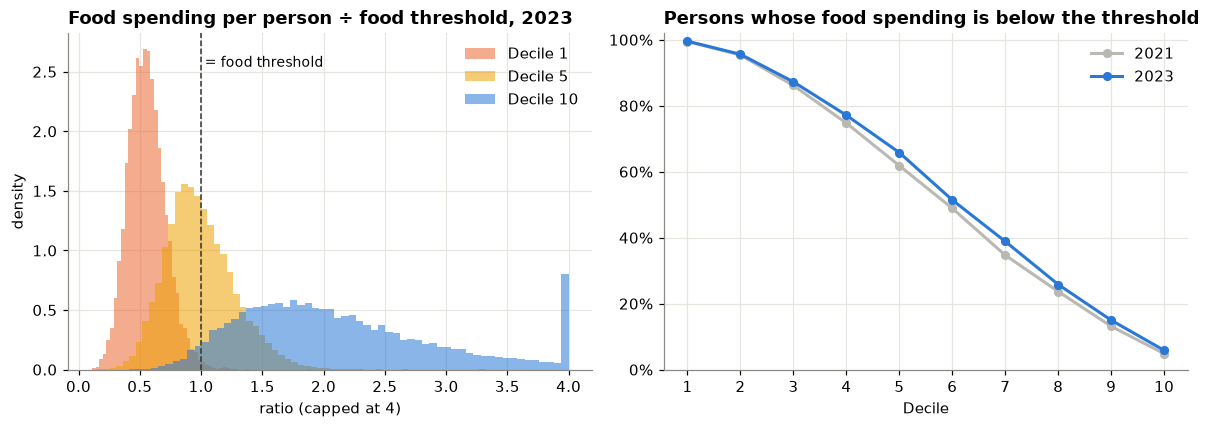

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for i, (dc, col) in enumerate([(1, PAL[1]), (5, PAL[3]), (10, PAL[0])]):
    x = d[d.decile == dc]
    ax[0].hist((x.food / x.fsize / x.food_threshold).clip(upper=4), bins=60, alpha=.55, color=col, label=f"Decile {dc}", density=True)
ax[0].axvline(1, color="#333", ls="--", lw=1); ax[0].text(1.03, ax[0].get_ylim()[1] * .9, "= food threshold", fontsize=9)
ax[0].set_title("Food spending per person ÷ food threshold, 2023"); ax[0].set_xlabel("ratio (capped at 4)"); ax[0].set_ylabel("density"); ax[0].legend()
for y, col in [(2021, MUTED), (2023, PAL[0])]:
    ax[1].plot(q2.index, q2[(y, "% of persons below threshold")], "o-", color=col, lw=2, ms=5, label=str(y))
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[1].set_ylim(0, 1.02); ax[1].set_xticks(range(1, 11))
ax[1].set_title("Persons whose food spending is below the threshold"); ax[1].set_xlabel("Decile"); ax[1].legend()
plt.tight_layout()

In [28]:
g = th.loc["PH"]
pd.DataFrame({"food threshold (PHP/yr)": [g.food_threshold_2021, g.food_threshold_2023],
              "mean food spending per person (PHP/yr)": [(fies[fies.year == y].food * fies[fies.year == y].rfact).sum() / (fies[fies.year == y].fsize * fies[fies.year == y].rfact).sum() for y in (2021, 2023)]},
             index=[2021, 2023]).pipe(lambda t: pd.concat([t, (t / t.iloc[0] - 1).add_prefix("growth since 2021: ")], axis=1))

,food threshold (PHP/yr),mean food spending per person (PHP/yr),growth since 2021: food threshold (PHP/yr),growth since 2021: mean food spending per person (PHP/yr)
2021,"20,046.000","23,093.063",0.000,0.000
2023,"22,994.000","25,727.588",0.147,0.114


**Findings, Q2.**
- **Most Filipinos spend less on food than the threshold.** In 2023, **56.2%** of Filipinos lived in households whose food consumption per person was below their region's PSA food threshold. The figure was 54.3% in 2021.
- **The poorest are almost all below it.** In decile 1, **99.6%** fall below the threshold, and the typical person consumes only **0.52×** the threshold, half of what a minimum nutritious menu costs.
- **The median person only reaches the threshold around decile 6.** Even in decile 5, 65.8% fall short.
- **The gap widened from 2021 to 2023.** The national food threshold rose **14.7%** while average food spending per person rose **11.4%**. The share below the threshold went up in every decile.

**Caveats.**
- This compares *consumption* with the cost of a *specific* least-cost menu. Households could in principle eat adequately for less by choosing differently. That is exactly what SAPAT tests.
- Home-produced food is valued at farm-gate prices, which understates the consumption of farming households.
- This is not the official subsistence incidence (2.7% of families in 2023), which compares *income*, not spending, with the threshold.

**What this changed.** For the poorest households a nutritious diet is not just a matter of better choices. The money is short. For the middle deciles it is close, so how the budget is used matters. Next we asked *where* the shortfall concentrates.

## EDA Q3: Do regions and urban/rural areas differ?

In [29]:
def region_tab(x):
    w = x.rfact
    return pd.Series({"households (weighted, M)": w.sum() / 1e6,
                      "food share of income": (x.food * w).sum() / (x.toinc * w).sum(),
                      "food PHP/person/day": (x.food * w).sum() / (x.fsize * w).sum() / 365,
                      "cereal % of home food": (x.bread * w).sum() / (x.food_home * w).sum(),
                      "animal-source % of home food": ((x.meat + x.fish + x.milk) * w).sum() / (x.food_home * w).sum(),
                      "% persons below food threshold": wavg(x.below_ft.astype(float).values, x.person_w.values),
                      "poverty incidence (families, %)": x.poverty_inc.iloc[0],
                      "% rural": wavg((x.area == "Rural").astype(float).values, w.values)})
q3 = fies[fies.year == 2023].groupby("region", observed=True).apply(region_tab).sort_values("poverty incidence (families, %)", ascending=False)
q3

,"households (weighted, M)",food share of income,food PHP/person/day,cereal % of home food,animal-source % of home food,% persons below food threshold,"poverty incidence (families, %)",% rural
region,,,,,,,,
IX Zamboanga Pen.,0.897,0.357,58.133,0.357,0.371,0.712,24.200,0.653
BARMM,0.837,0.470,56.591,0.344,0.298,0.598,23.500,0.719
V Bicol,1.374,0.303,54.453,0.338,0.387,0.749,20.300,0.746
VIII Eastern Visayas,1.185,0.332,58.201,0.349,0.387,0.682,20.300,0.854
X Northern Mindanao,1.236,0.281,54.106,0.357,0.381,0.745,18.400,0.491
XII SOCCSKSARGEN,1.138,0.309,58.482,0.337,0.373,0.588,17.000,0.421
MIMAROPA,0.819,0.299,55.124,0.339,0.382,0.655,16.300,0.663
XIII Caraga,0.694,0.349,61.827,0.330,0.406,0.544,14.900,0.666
VII Central Visayas,2.053,0.277,58.916,0.344,0.403,0.699,12.300,0.452


In [30]:
print("Pearson and Spearman correlation across the 17 regions (2023):")
pd.DataFrame({m: q3.drop(columns="households (weighted, M)").corr(method=m)["poverty incidence (families, %)"] for m in ["pearson", "spearman"]}).drop("poverty incidence (families, %)").round(3)

Pearson and Spearman correlation across the 17 regions (2023):


,pearson,spearman
food share of income,0.582,0.569
food PHP/person/day,-0.780,-0.815
cereal % of home food,0.877,0.857
animal-source % of home food,-0.843,-0.901
% persons below food threshold,0.746,0.754
% rural,0.541,0.470


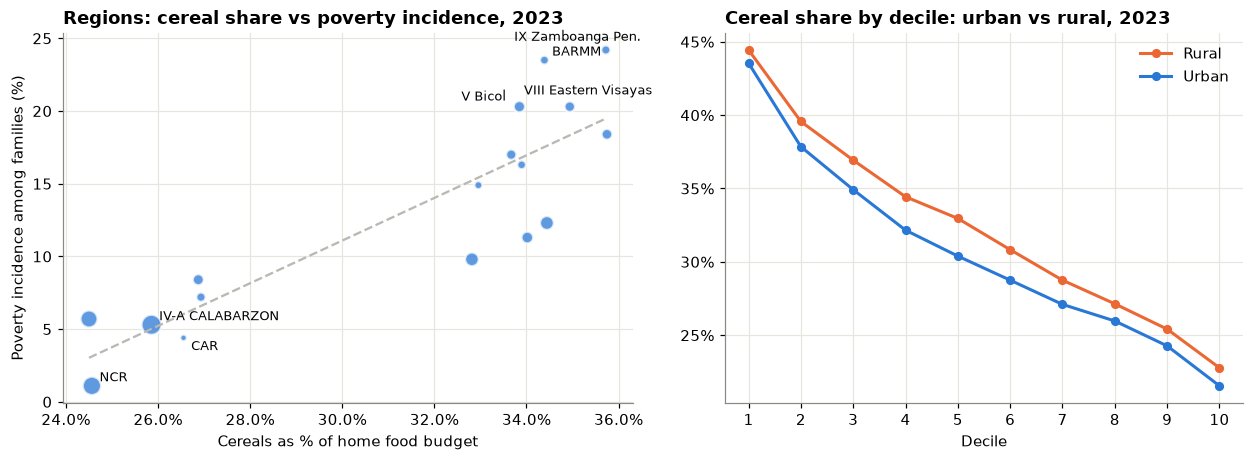

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1.1, 1]})
x, y = q3["cereal % of home food"], q3["poverty incidence (families, %)"]
ax[0].scatter(x, y, s=q3["households (weighted, M)"] * 40, color=PAL[0], alpha=.75, edgecolor="white", linewidth=1.5)
b = np.polyfit(x, y, 1); xs = np.linspace(x.min(), x.max(), 50); ax[0].plot(xs, np.polyval(b, xs), color=MUTED, lw=1.5, ls="--")
for r, off in {"BARMM": (5, 3), "NCR": (5, 3), "IX Zamboanga Pen.": (-60, 6), "V Bicol": (-38, 4), "IV-A CALABARZON": (5, 3),
               "VIII Eastern Visayas": (-30, 8), "CAR": (5, -8)}.items():
    ax[0].annotate(r, (x[r], y[r]), xytext=off, textcoords="offset points", fontsize=8.5)
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[0].set_title("Regions: cereal share vs poverty incidence, 2023"); ax[0].set_xlabel("Cereals as % of home food budget"); ax[0].set_ylabel("Poverty incidence among families (%)")

ua = fies[fies.year == 2023].groupby(["decile", "area"]).apply(lambda z: (z.bread * z.rfact).sum() / (z.food_home * z.rfact).sum()).unstack()
for i, a in enumerate(["Rural", "Urban"]):
    ax[1].plot(ua.index, ua[a], "o-", color=PAL[[1, 0][i]], lw=2, ms=5, label=a)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax[1].set_xticks(range(1, 11))
ax[1].set_title("Cereal share by decile: urban vs rural, 2023"); ax[1].set_xlabel("Decile"); ax[1].legend()
plt.tight_layout()

In [32]:
ur = fies[fies.year == 2023].groupby("area").apply(lambda z: pd.Series({
    "persons (M)": z.person_w.sum() / 1e6,
    "median food share of income": wquantile(z.food_share_inc, z.rfact, .5),
    "median food PHP/person/day": wquantile(z.food_pc_day, z.person_w, .5),
    "median cereal share": wquantile(z.sh_cereal, z.rfact, .5),
    "median animal-source share": wquantile(z.sh_animal, z.rfact, .5),
    "% persons below threshold": wavg(z.below_ft.astype(float).values, z.person_w.values),
    "mean farm/fishing income share": wavg(z.inc_agri.values, z.rfact.values),
    "mean remittance share": wavg(z.inc_abroad.values, z.rfact.values),
}))
ur.T

area,Rural,Urban
persons (M),50.462,62.320
median food share of income,0.389,0.332
median food PHP/person/day,52.775,69.938
median cereal share,0.331,0.276
median animal-source share,0.377,0.411
% persons below threshold,0.668,0.477
mean farm/fishing income share,0.131,0.028
mean remittance share,0.066,0.067


**Findings, Q3.**
- **Diet composition, more than food share, tracks regional poverty.** Across the 17 regions in 2023, poverty incidence correlates with:
  - the **cereal share** of the home food budget: Pearson **r = 0.88**, Spearman **0.86**;
  - the **animal-source share**: Spearman **−0.90**;
  - **food spending per person per day**: Spearman −0.82;
  - the **share of people below the food threshold**: 0.75;
  - **food's share of income**: only 0.57.
- **Mindanao and Eastern Visayas stand out.** Zamboanga Peninsula, BARMM, Bicol and Eastern Visayas combine the highest poverty with cereal shares of 34–36%. NCR, CALABARZON and Central Luzon spend about 25% on cereals.
- **BARMM is the extreme case for burden.** It spends **47%** of income on food, the highest of any region, and has the lowest animal-source share (29.8%).
- **Rural households are worse off on every measure.** Compared with urban households:

  | Measure (2023) | Rural | Urban |
  |---|---|---|
  | Median food share of income | 38.9% | 33.2% |
  | Median food spending per person per day | PHP 52.78 | PHP 69.94 |
  | Median cereal share | 33.1% | 27.6% |
  | Persons below the food threshold | 66.8% | 47.7% |

- **Location matters even at the same income.** Within *every* income decile, rural households spend a higher share on cereals than urban ones.

**What this changed.** The pattern is regional and rural, not only about income. That points to livelihood: rural households farm and fish. So we asked which household characteristics go with a heavy burden.

## EDA Q4: Which household characteristics go with a heavy food burden?
We split 2023 households into quartiles of food share of income (Q4 = heaviest burden) and compare their income sources, size and diet. A correlation matrix then shows how these features move together across all households.

In [33]:
d = fies[fies.year == 2023].copy()
d["burden_q"] = pd.qcut(d.food_share_inc, 4, labels=["Q1 lightest", "Q2", "Q3", "Q4 heaviest"])
feat = ["pcinc", "fsize", "inc_wages", "inc_abroad", "inc_domestic", "inc_agri", "inc_enterprise", "sh_cereal", "sh_animal", "sh_outside"]
q4 = pd.concat([d.groupby("burden_q", observed=True)[["pcinc", "fsize"]].median().T.rename(index=lambda i: i + " (median)"),
                d.groupby("burden_q", observed=True)[feat[2:]].mean().T.rename(index=lambda i: i + " (mean)")])
q4["Q4 / Q1"] = q4["Q4 heaviest"] / q4["Q1 lightest"]
print("Food-burden quartiles, 2023 (unweighted sample). Income-source shares are means because most households have 0 for most sources.")
q4

Food-burden quartiles, 2023 (unweighted sample). Income-source shares are means because most households have 0 for most sources.


burden_q,Q1 lightest,Q2,Q3,Q4 heaviest,Q4 / Q1
pcinc (median),"138,616.156","76,310.289","54,406.000","39,214.168",0.283
fsize (median),3.500,4.000,4.000,4.000,1.143
inc_wages (mean),0.537,0.517,0.478,0.406,0.756
inc_abroad (mean),0.086,0.070,0.055,0.037,0.425
inc_domestic (mean),0.041,0.067,0.092,0.119,2.921
inc_agri (mean),0.046,0.073,0.103,0.176,3.823
inc_enterprise (mean),0.112,0.111,0.115,0.108,0.961
sh_cereal (mean),0.292,0.315,0.331,0.349,1.194
sh_animal (mean),0.404,0.393,0.383,0.369,0.912
sh_outside (mean),0.113,0.096,0.085,0.071,0.631


In [34]:
print("Share of households with any income from each source, by burden quartile")
d.assign(any_abroad=d.cash_abroad > 0, any_agri=d.inc_agri > 0, any_wages=d.wages > 0, any_domestic=d.cash_domestic > 0, rural=d.area == "Rural") \
 .groupby("burden_q", observed=True)[["any_wages", "any_abroad", "any_domestic", "any_agri", "rural"]].mean().T

Share of households with any income from each source, by burden quartile


burden_q,Q1 lightest,Q2,Q3,Q4 heaviest
any_wages,0.834,0.828,0.801,0.728
any_abroad,0.320,0.277,0.238,0.180
any_domestic,0.500,0.632,0.713,0.773
any_agri,0.212,0.270,0.331,0.450
rural,0.396,0.471,0.556,0.675


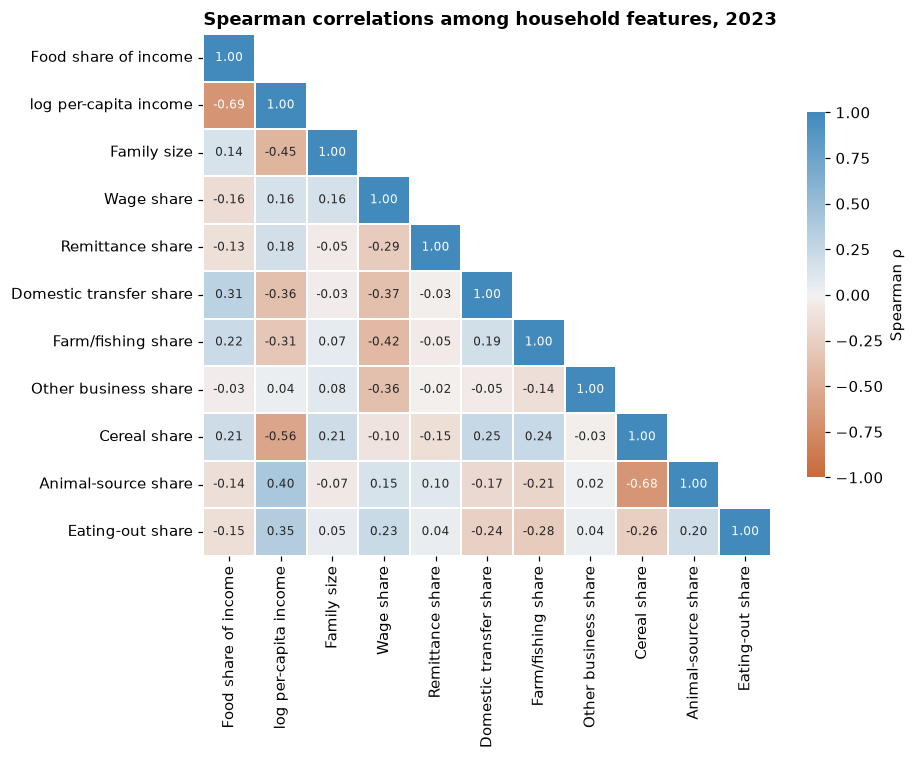

In [35]:
cols = {"food_share_inc": "Food share of income", "log_pcinc": "log per-capita income", "fsize": "Family size",
        "inc_wages": "Wage share", "inc_abroad": "Remittance share", "inc_domestic": "Domestic transfer share",
        "inc_agri": "Farm/fishing share", "inc_enterprise": "Other business share", "sh_cereal": "Cereal share",
        "sh_animal": "Animal-source share", "sh_outside": "Eating-out share"}
cm = d[list(cols)].rename(columns=cols).corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
mask = np.triu(np.ones_like(cm, dtype=bool), 1)
sns.heatmap(cm, mask=mask, cmap=sns.diverging_palette(28, 240, s=80, l=55, as_cmap=True), vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=1, linecolor="white", cbar_kws={"shrink": .7, "label": "Spearman ρ"}, ax=ax)
ax.set_title("Spearman correlations among household features, 2023"); ax.grid(False)
plt.tight_layout()

findfont: Failed to find font weight semibold, now using 700.


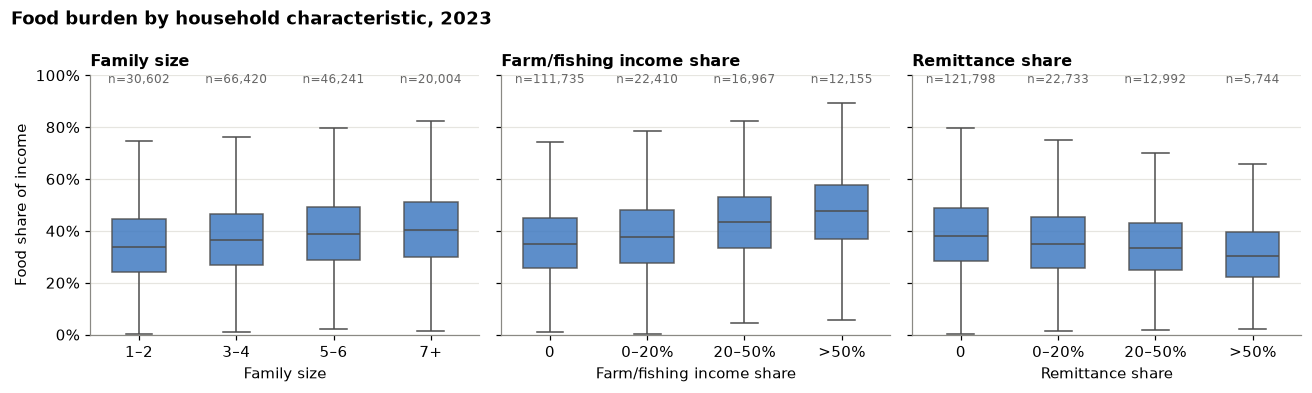

In [36]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for a, (c, lab) in zip(ax, [("fsize", "Family size"), ("inc_agri", "Farm/fishing income share"), ("inc_abroad", "Remittance share")]):
    bins = pd.cut(d[c], [-.01, 2, 4, 6, 30] if c == "fsize" else [-.01, 0, .2, .5, 1.01],
                  labels=["1–2", "3–4", "5–6", "7+"] if c == "fsize" else ["0", "0–20%", "20–50%", ">50%"])
    sns.boxplot(x=bins, y=d.food_share_inc, ax=a, color=PAL[0], fliersize=0, width=.55, linewidth=1, boxprops=dict(alpha=.85))
    a.set_xlabel(lab); a.set_ylabel(""); a.set_title(lab, fontsize=10.5)
    for i, (k, n) in enumerate(bins.value_counts(sort=False).items()):
        a.text(i, .97, f"n={n:,}", ha="center", fontsize=8, color="#666")
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1)); ax[0].set_ylim(0, 1); ax[0].set_ylabel("Food share of income")
plt.suptitle("Food burden by household characteristic, 2023", x=.01, ha="left", fontweight="semibold"); plt.tight_layout()

**Findings, Q4.**
- **Heaviest-burden households are poorer.** Q4 households (top quarter by food share) have a median per-capita income of PHP 39,214, against PHP 138,616 for Q1. Their families are slightly larger (median 4 vs 3.5).
- **They live on different incomes.** Q4 compared with Q1 (lightest burden):

  | Income measure | Q1 lightest | Q4 heaviest |
  |---|---|---|
  | Households with farm or fishing income | 21% | 45% |
  | Average farm/fishing share of income | 4.6% | 17.6% |
  | Households receiving domestic cash transfers | 50% | 77% |
  | Average share from domestic transfers | 4.1% | 11.9% |
  | Households receiving remittances from abroad | 32% | 18% |
  | Average wage share of income | 54% | 41% |
  | Households that are rural | 40% | 68% |

- **Correlations point the same way.** Food share correlates with the domestic-transfer share (ρ = 0.31), farm/fishing share (0.22) and family size (0.14). It correlates negatively with the remittance share (−0.13).
- **The boxplots show steady gradients.** Median food share rises from about 35% for households with no farm income to about 48% for those earning more than half their income from farming or fishing. It falls as the remittance share grows, and rises with family size.
- **Burden and diet move together.** Q4 households put 34.9% of the home food budget into cereals, against 29.2% for Q1. Cereal and animal-source shares are strongly opposed (ρ = −0.68).

**Caution.** These features are correlated with income and with each other. Farm households are poorer and more rural. EDA alone cannot say which matters independently. Data mining (clustering into household profiles) and statistical tests are needed to separate them.

## EDA Q5: How have food prices moved, and what does a peso buy?

In [37]:
KEY = {"RICE, REGULAR-MILLED, 1 KG": "Rice, regular-milled", "MONGGO, GREEN, 1 KG": "Mung beans",
       "FRESH EGG, CHICKEN, MEDIUM, 1 PC": "Chicken egg", "FRESH FISH, ROUND SCAD, GALUNGGONG, MEDIUM, 1 KG": "Galunggong",
       "FRESH CHICKEN, FULLY DRESSED, BROILER, 1 KG": "Chicken, whole", "FRESH PORK, KASIM, 1 KG": "Pork kasim",
       "SRA REFINED SUGAR, 1 KG": "Refined sugar (SRA)"}
kp = nat[nat.commodity.isin(KEY)].assign(food=lambda x: x.commodity.map(KEY)).pivot_table(index="date", columns="food", values="price")
base = kp.loc["2018"].mean() if kp.loc["2018"].notna().all().all() else kp.apply(lambda s: s.dropna().iloc[:12].mean())
idx = kp / base * 100
last = kp.index.max()
q5a = pd.DataFrame({"latest price (PHP)": kp.loc[last], "vs 2018 average": kp.loc[last] / base - 1,
                    "vs 12 months earlier": kp.loc[last] / kp.loc[last - pd.DateOffset(years=1)] - 1,
                    "CV over 2018–2026": kp.std() / kp.mean()}).sort_values("vs 2018 average", ascending=False)
print("Latest month:", last.strftime("%B %Y"), "| eggs priced per piece")
q5a

Latest month: September 2026 | eggs priced per piece


,latest price (PHP),vs 2018 average,vs 12 months earlier,CV over 2018–2026
food,,,,
Galunggong,242.390,0.699,0.059,0.168
Chicken egg,9.130,0.461,-0.027,0.144
Refined sugar (SRA),81.538,0.404,-0.037,0.201
Pork kasim,321.340,0.400,-0.097,0.148
Mung beans,124.550,0.376,0.120,0.094
"Chicken, whole",213.240,0.368,-0.010,0.122
"Rice, regular-milled",50.100,0.155,0.245,0.102


findfont: Failed to find font weight semibold, now using 700.


Refined sugar starts Sep 2018, so its base is its first 12 months. Grey lines are the other foods, for comparison.


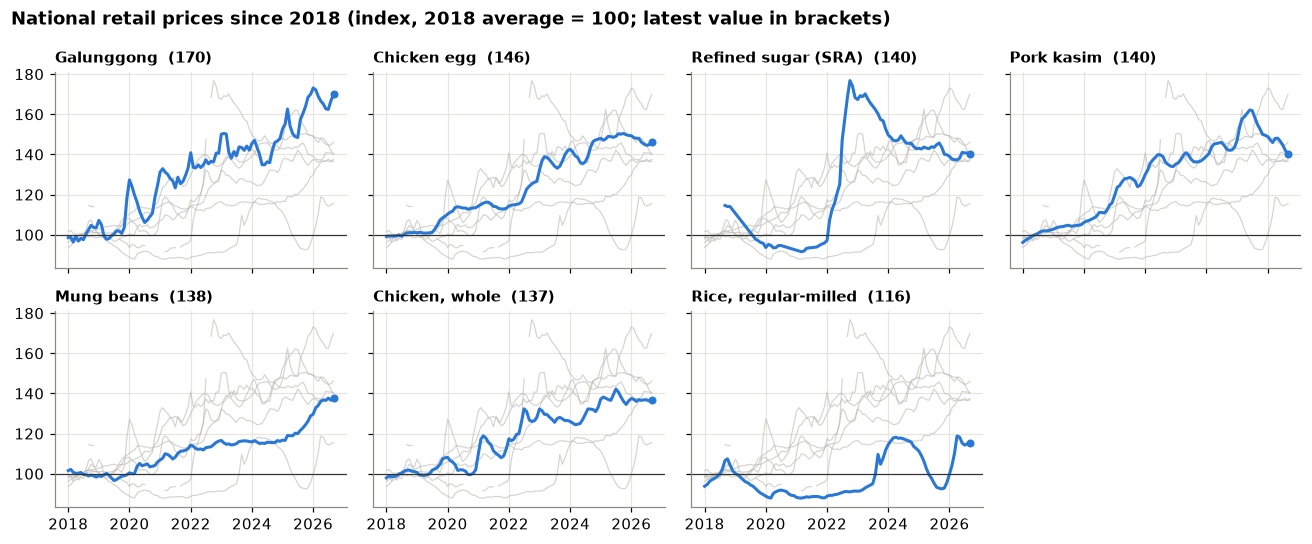

In [38]:
order = q5a.index.tolist()
fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharey=True, sharex=True)
for a, c in zip(axes.flat, order):
    for o in order:                                   # all series faint for context
        if o != c: a.plot(idx.index, idx[o], color=MUTED, lw=.8, alpha=.6)
    s = idx[c].dropna(); a.plot(s.index, s, color=PAL[0], lw=2)
    a.axhline(100, color="#333", lw=.8); a.scatter(s.index[-1], s.iloc[-1], color=PAL[0], s=18, zorder=3)
    a.set_title(f"{c}  ({s.iloc[-1]:.0f})", fontsize=10)
import matplotlib.dates as mdates
for a in axes.flat[:-1]:
    a.xaxis.set_major_locator(mdates.YearLocator(2)); a.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes.flat[-1].set_visible(False)
fig.suptitle("National retail prices since 2018 (index, 2018 average = 100; latest value in brackets)", x=.01, ha="left", fontweight="semibold")
plt.tight_layout()
print("Refined sugar starts Sep 2018, so its base is its first 12 months. Grey lines are the other foods, for comparison.")

                count    min    50%    max
food_group                                
cereals         6.000  5.070  6.460  8.600
eggs            2.000 15.410 15.830 16.250
fish & seafood 12.000 13.990 22.890 75.340
meat            8.000 18.870 21.950 47.990
pulses & nuts   3.000  4.790  5.360  9.940


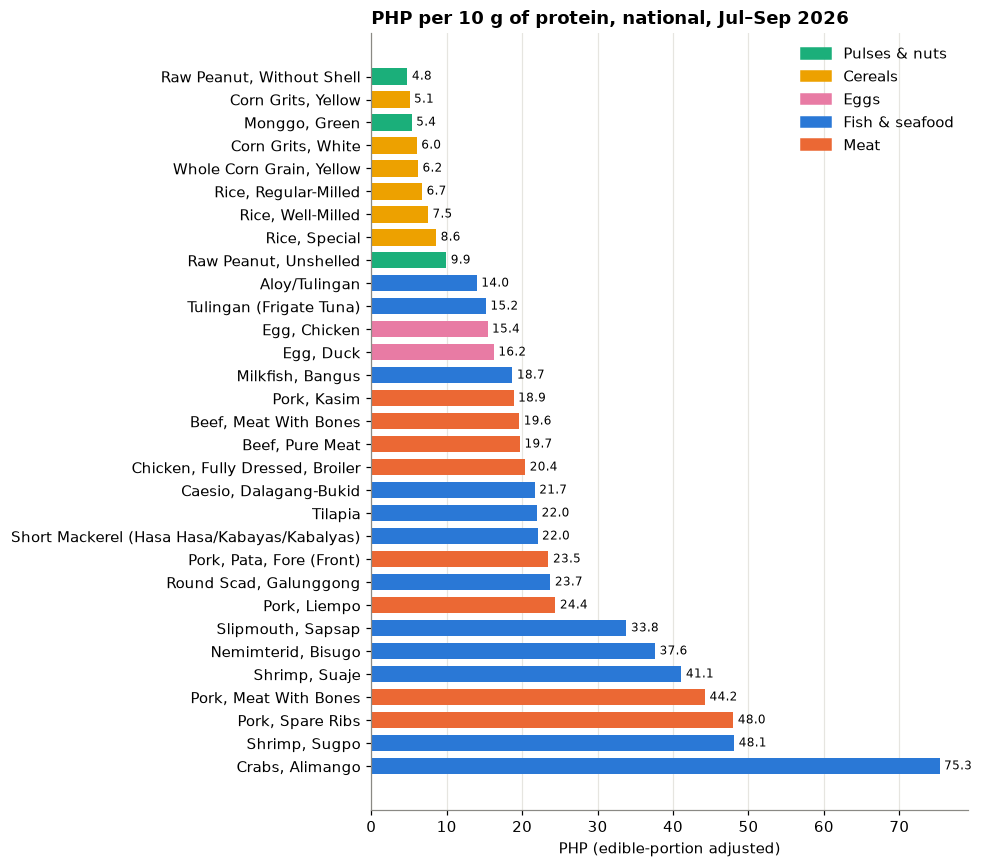

In [39]:
recent = nat_n[nat_n.date > nat_n.date.max() - pd.DateOffset(months=3)]
pq = recent.groupby(["commodity", "food_group"], as_index=False).agg(php_per_10g_protein=("php_per_10g_protein", "mean"), ep_pct=("ep_pct", "first"),
                                                                    price=("price", "mean"))
pq = pq[pq.food_group.isin(["meat", "fish & seafood", "eggs", "pulses & nuts", "cereals"])].sort_values("php_per_10g_protein")
pq["food"] = pq.commodity.str.replace(r", (MEDIUM, )?1 (KG|PC)$", "", regex=True).str.replace("FRESH FISH, |FRESH ", "", regex=True).str.title()
print(pq.groupby("food_group").php_per_10g_protein.describe()[["count", "min", "50%", "max"]].round(2))

fig, ax = plt.subplots(figsize=(9, 8))
gcol = {"pulses & nuts": PAL[2], "cereals": PAL[3], "eggs": PAL[4], "fish & seafood": PAL[0], "meat": PAL[1]}
ax.barh(pq.food, pq.php_per_10g_protein, color=pq.food_group.map(gcol), height=.7)
for yv, v in enumerate(pq.php_per_10g_protein): ax.text(v + .6, yv, f"{v:.1f}", va="center", fontsize=8)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_title(f"PHP per 10 g of protein, national, {recent.date.min():%b}–{recent.date.max():%b %Y}"); ax.set_xlabel("PHP (edible-portion adjusted)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in gcol.values()], labels=[k.capitalize() for k in gcol], loc="upper right")
plt.tight_layout()

In [40]:
cov = reg_n[reg_n.place != "Negros Island Region (NIR)"].groupby(["commodity", "place"]).date.nunique() / nat_n.date.nunique()
cov = cov.unstack(fill_value=0)
cov_summary = pd.DataFrame({"regions priced (any month)": (cov > 0).sum(axis=1), "mean coverage across regions": cov.mean(axis=1)}).sort_values("mean coverage across regions")
print(f"{(cov.min(axis=1) >= .9).sum()} of {len(cov)} mapped foods have >=90% monthly coverage in all 17 regions")
cov_summary.head(12)

24 of 62 mapped foods have >=90% monthly coverage in all 17 regions


,regions priced (any month),mean coverage across regions
commodity,,
"RAW PEANUT, WITHOUT SHELL, 1 KG",1,0.059
"FRESH FISH, SHORT MACKEREL (HASA HASA/KABAYAS/KABALYAS), MEDIUM, 1 KG",3,0.176
"FRESH PORK, PATA, FORE (FRONT), 1 KG",4,0.235
"FRESH FRUIT, MANGO, PIKO, RIPE, MEDIUM, 1 KG",4,0.235
"PECHAY, CHINESE, 1 KG",4,0.235
"FRESH FRUIT, PAPAYA, MEDIUM, 1 KG",5,0.294
"FRESH FISH, TULINGAN (FRIGATE TUNA), MEDIUM, 1 KG",5,0.294
"FRESH PORK, SPARE RIBS, 1 KG",5,0.294
"FRESH EGG, DUCK, MEDIUM, 1 PC",6,0.353


**Findings, Q5.**
- **Almost every key food is much dearer than in 2018.** National prices in September 2026, against their 2018 average:

  | Food | Change since 2018 |
  |---|---|
  | Galunggong | **+70%** |
  | Chicken eggs | +46% |
  | Pork kasim | +40% |
  | Refined sugar | +40% (base Sep 2018–Aug 2019) |
  | Mung beans | +38% |
  | Whole chicken | +37% |
  | Regular-milled rice | **+16%** |

- **Rice is the most volatile.** It fell below its 2018 level for most of 2019–2022, then spiked twice. It is now **+24.5% year on year** at PHP 50.10/kg.
- **Protein costs very different amounts by food** (national, July–September 2026, edible-portion adjusted):
  - **Under PHP 10 per 10 g:** shelled peanuts (4.8), mung beans (5.4), corn grits and rice (5–9).
  - **Eggs:** PHP 15–16.
  - **Fish:** median **PHP 22.9**, from 14.0 for tulingan to 75.3 for crab.
  - **Meat:** median **PHP 22.0**.
  - The animal sources poorer households rely on (galunggong, tilapia, chicken) cost **PHP 20–24**, about **four times** the legumes.
- **What that means for the poorest decile.** For illustration, 50 g of protein a day would cost about PHP 27 from mung beans, PHP 77 from eggs or PHP 119 from galunggong. Decile 1's *entire* food budget is about PHP 33 per person per day.
- **Cheap staples carry protein on paper.** Rice and corn appear among the cheapest protein sources, but cereal protein is lower in quality. This must be handled in any diet model.
- **Regional price data are patchy.** Only **24 of 62** mapped foods are priced in at least 90% of months in every region. Cheap foods such as corn grits, camote and small fish are the patchiest.

## 3.2 Refined research question

**From the starting question to the research question.**
- **Q1–Q2.** The problem is mainly a budget gap, not ignorance. Most Filipinos, and almost all of the poorest, consume less food per person than the PSA's minimum nutritious menu costs. Their pesos go mostly to rice.
- **Q3–Q4.** The gap is not explained by income alone. It concentrates in rural areas and specific regions (Mindanao, Eastern Visayas, Bicol), and in households living on farming, fishing and domestic transfers rather than wages or remittances.
- **Q5.** Prices make the gap hard to close. Animal protein costs about four times as much per gram as legumes, and every protein source has become dearer since 2018.

> **Research question:** *What characterizes the Filipino households that carry the heaviest food burden and the most staple-heavy food budgets, in terms of income, livelihood, location and household size? And at current prices, how far can their food budgets go toward an adequate, protein-sufficient diet?*

This question is broad enough to need the whole dataset, and it feeds SAPAT directly. It tells the app *who* to design for and *which* foods give them the most nutrition per peso.

**How the next sections answer it:**
- **Section 4, Data Mining.** k-means clustering groups households into food-budget profiles, to see *which kinds of households* carry the burden.
- **Section 5, Statistical Inference.** Five tests check whether the patterns from the EDA and the clusters are statistically real or could be chance.

---
# 4. Data Mining: household food-budget profiles

The EDA showed that food burden is tied to income, location, livelihood and household size at the same time, and these overlap. Looking at one variable at a time can't show which *combinations* of characteristics occur together in real households. So we use **clustering** to let the data group similar households, then describe each group.

## 4.1 Technique: k-means clustering
**k-means** splits *n* observations into *k* clusters. It does this by minimizing the **within-cluster sum of squares (WCSS)**, the total squared Euclidean distance from each point to the centre (centroid) of its cluster:

$$\min_{C_1,\dots,C_k} \sum_{j=1}^{k} \sum_{x_i \in C_j} \lVert x_i - \mu_j \rVert^2$$

Lloyd's algorithm alternates two steps until nothing changes:
1. assign each household to the nearest centroid;
2. move each centroid to the mean of its households.

Each round can only lower WCSS, so the algorithm always converges, but possibly to a *local* minimum. We therefore start the centroids with **k-means++**, which spreads the starting centroids apart, and keep the best of **10 random restarts** (`n_init=10`).

**Why k-means fits this data:** all features are numeric, the sample is large (163,267 households), and each centroid is a "typical household" that is easy to describe. **Its limits:** it uses Euclidean distance, so features must be on the same scale (Step 4.2), and it favours compact, similarly sized clusters.

## 4.2 Preprocessing
We cluster the **2023** households on 13 features describing *who the household is* and *how it uses its food budget*:

| Group | Features | Preprocessing |
|---|---|---|
| Income level | `log_pcinc` | **log10** transform (raw income is extremely right-skewed, skewness 115) |
| Household | `fsize`, `rural` (0/1) | `rural` one-hot encoded from `area` |
| Food burden | `food_share_inc` | truncated at 1 (Section 2) |
| Diet composition | `sh_cereal`, `sh_animal`, `sh_veg_fruit`, `sh_outside` | shares, already bounded 0–1 |
| Livelihood | `inc_wages`, `inc_abroad`, `inc_domestic`, `inc_agri`, `inc_enterprise` | shares of income; losses clipped at 0 |

**Every feature is then standardized to mean 0 and standard deviation 1 (z-scores).** Without this, family size (ranging 1 to 23) would dominate the distance and shares (0 to 1) would barely count. Survey weights are **not** used to fit the clusters, because they describe how the sample relates to the population, not how similar households are. They are used afterwards to describe each cluster in population terms.

In [41]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

h = fies[fies.year == 2023].copy().reset_index(drop=True)
h["rural"] = (h.area == "Rural").astype(int)
FEAT = ["log_pcinc", "fsize", "rural", "food_share_inc", "sh_cereal", "sh_animal", "sh_veg_fruit", "sh_outside",
        "inc_wages", "inc_abroad", "inc_domestic", "inc_agri", "inc_enterprise"]
assert h[FEAT].notna().all().all()
scaler = StandardScaler()
X = scaler.fit_transform(h[FEAT])
pd.DataFrame({"mean before": h[FEAT].mean(), "sd before": h[FEAT].std(),
              "mean after": X.mean(axis=0), "sd after": X.std(axis=0)}).round(3)

,mean before,sd before,mean after,sd after
log_pcinc,4.847,0.311,0.000,1.000
fsize,4.136,1.967,-0.000,1.000
rural,0.524,0.499,0.000,1.000
food_share_inc,0.379,0.145,0.000,1.000
sh_cereal,0.322,0.107,0.000,1.000
sh_animal,0.387,0.104,-0.000,1.000
sh_veg_fruit,0.128,0.055,0.000,1.000
sh_outside,0.091,0.115,0.000,1.000
inc_wages,0.484,0.337,-0.000,1.000
inc_abroad,0.062,0.152,-0.000,1.000


## 4.3 Choosing *k*
We fit k = 2 to 10 and compare two criteria:
- **Elbow method:** WCSS (inertia) always falls as *k* grows. We look for the point where extra clusters stop buying much reduction.
- **Silhouette coefficient:** for each point, $s = (b - a) / \max(a, b)$, where *a* is the mean distance to its own cluster and *b* is the mean distance to the nearest other cluster. It ranges from −1 to 1, and higher means better-separated clusters. It costs O(n²), so it is computed on a random sample of 15,000 households.

In [42]:
rng = np.random.default_rng(7)
sil_idx = rng.choice(len(X), 15_000, replace=False)
scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    scores.append({"k": k, "inertia (WCSS)": km.inertia_, "silhouette": silhouette_score(X[sil_idx], km.labels_[sil_idx])})
scores = pd.DataFrame(scores).set_index("k")
scores["WCSS drop vs k-1"] = -scores["inertia (WCSS)"].pct_change()
scores

,inertia (WCSS),silhouette,WCSS drop vs k-1
k,,,
2,"1,778,591.728",0.155,NaN
3,"1,627,999.612",0.148,0.085
4,"1,503,361.816",0.170,0.077
5,"1,377,595.826",0.151,0.084
6,"1,276,477.738",0.168,0.073
7,"1,213,019.510",0.151,0.050
8,"1,157,802.384",0.141,0.046
9,"1,113,051.284",0.138,0.039
10,"1,079,298.296",0.137,0.030


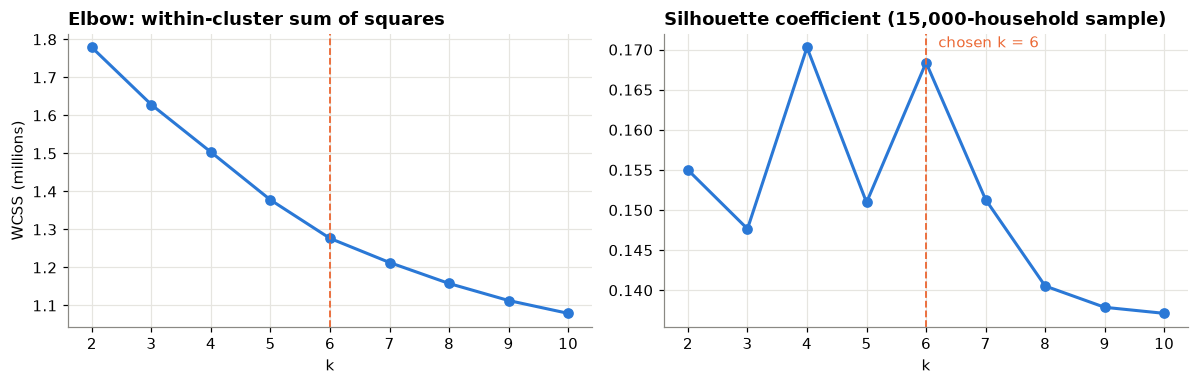

In [43]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(scores.index, scores["inertia (WCSS)"] / 1e6, "o-", color=PAL[0], lw=2)
ax[0].set_title("Elbow: within-cluster sum of squares"); ax[0].set_xlabel("k"); ax[0].set_ylabel("WCSS (millions)")
ax[1].plot(scores.index, scores["silhouette"], "o-", color=PAL[0], lw=2)
ax[1].set_title("Silhouette coefficient (15,000-household sample)"); ax[1].set_xlabel("k")
for a in ax: a.axvline(6, color=PAL[1], ls="--", lw=1.2); a.set_xticks(scores.index)
ax[1].annotate("chosen k = 6", (6, scores.loc[6, "silhouette"]), xytext=(8, 10), textcoords="offset points", color=PAL[1])
plt.tight_layout()

**Choosing k = 6.**
- **Elbow.** Each added cluster cuts WCSS by 7–8% up to k = 6. From k = 7 on, each one buys only 3–5%, so the curve bends after six.
- **Silhouette.** It peaks at k = 4 (0.170), and k = 6 is almost as high (0.168). Values below 0.25 are normal for survey data like this: households form a continuum with overlapping groups, not islands. The clusters are useful *profiles*, not sharply separated types.
- **Why 6 over 4.** At k = 4, farming, transfer-dependent and low-wage wage-earning households fall into one mixed cluster. The EDA showed these livelihoods behave differently, so k = 6 is the more informative choice at almost the same silhouette.

## 4.4 Fitting the final model and profiling the clusters

In [44]:
K = 6
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
h["cluster"] = km.labels_

def profile(z):
    w = z.rfact
    out = {f: wavg(z[f].values, w.values) for f in FEAT if f != "log_pcinc"}
    out.update({
        "median pc income (PHP/yr)": wquantile(z.pcinc, z.person_w, .5),
        "food PHP/person/day": (z.food * w).sum() / (z.fsize * w).sum() / 365,
        "% persons below food threshold": wavg(z.below_ft.astype(float).values, z.person_w.values),
        "% of Filipinos": z.person_w.sum() / h.person_w.sum(),
        "sample households": len(z),
    })
    return pd.Series(out)
prof = h.groupby("cluster").apply(profile)

# Name each cluster by its defining trait (rule-based, so the names do not depend on the arbitrary label numbers)
def name(r):
    if r.inc_agri > .4: return "Farming & fishing"
    if r.inc_abroad > .4: return "OFW remittance"
    if r.inc_enterprise > .4: return "Small business"
    if r.inc_domestic > .3: return "Transfer-dependent"
    return "wage"
names = prof.apply(name, axis=1)
wage = names[names == "wage"].index
hi_w = prof.loc[wage, "median pc income (PHP/yr)"].idxmax()
names[hi_w] = "Better-off wage earners"
names[(names == "wage")] = "Low-wage large families"
assert names.is_unique, names
h["profile"] = h.cluster.map(names)
prof.index = prof.index.map(names)
ORDER = prof.sort_values("% persons below food threshold", ascending=False).index.tolist()
prof = prof.loc[ORDER]
prof.T

cluster,Low-wage large families,Farming & fishing,Transfer-dependent,Small business,OFW remittance,Better-off wage earners
fsize,5.123,4.252,2.789,3.908,3.373,3.814
rural,0.635,0.823,0.706,0.354,0.457,0.196
food_share_inc,0.420,0.469,0.428,0.365,0.302,0.306
sh_cereal,0.391,0.381,0.342,0.298,0.264,0.251
sh_animal,0.347,0.331,0.359,0.397,0.428,0.441
sh_veg_fruit,0.106,0.135,0.135,0.130,0.137,0.133
sh_outside,0.065,0.041,0.057,0.100,0.106,0.171
inc_wages,0.694,0.122,0.160,0.149,0.160,0.753
inc_abroad,0.020,0.022,0.033,0.027,0.518,0.023
inc_domestic,0.062,0.083,0.409,0.047,0.044,0.023


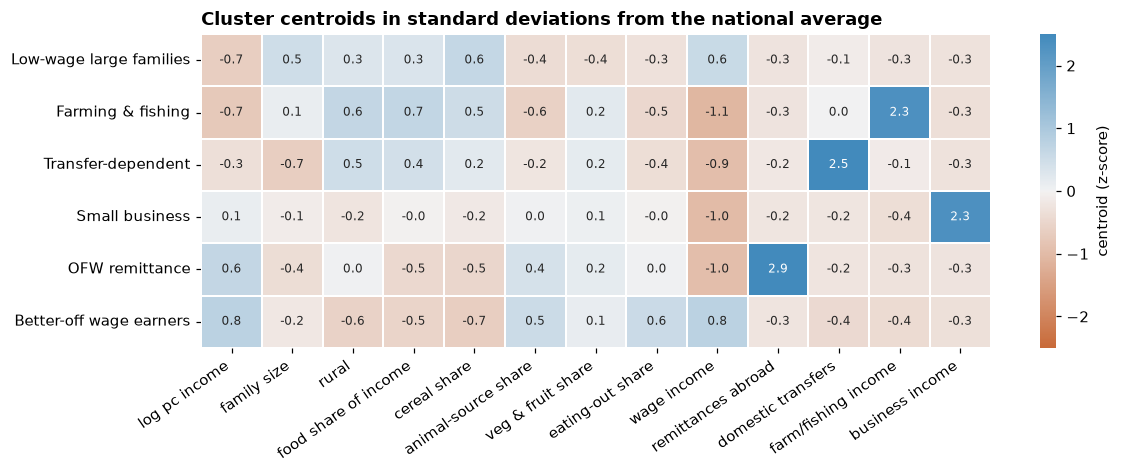

In [45]:
cent = pd.DataFrame(km.cluster_centers_, columns=FEAT, index=[names[i] for i in range(K)]).loc[ORDER]
labels = {"log_pcinc": "log pc income", "fsize": "family size", "rural": "rural", "food_share_inc": "food share of income",
          "sh_cereal": "cereal share", "sh_animal": "animal-source share", "sh_veg_fruit": "veg & fruit share", "sh_outside": "eating-out share",
          "inc_wages": "wage income", "inc_abroad": "remittances abroad", "inc_domestic": "domestic transfers", "inc_agri": "farm/fishing income",
          "inc_enterprise": "business income"}
fig, ax = plt.subplots(figsize=(11, 4.4))
sns.heatmap(cent.rename(columns=labels), cmap=sns.diverging_palette(28, 240, s=80, l=55, as_cmap=True), center=0, vmin=-2.5, vmax=2.5,
            annot=True, fmt=".1f", annot_kws={"size": 8}, linewidths=1, linecolor="white", cbar_kws={"label": "centroid (z-score)"}, ax=ax)
ax.set_title("Cluster centroids in standard deviations from the national average"); ax.set_ylabel(""); ax.grid(False)
plt.xticks(rotation=35, ha="right"); plt.tight_layout()

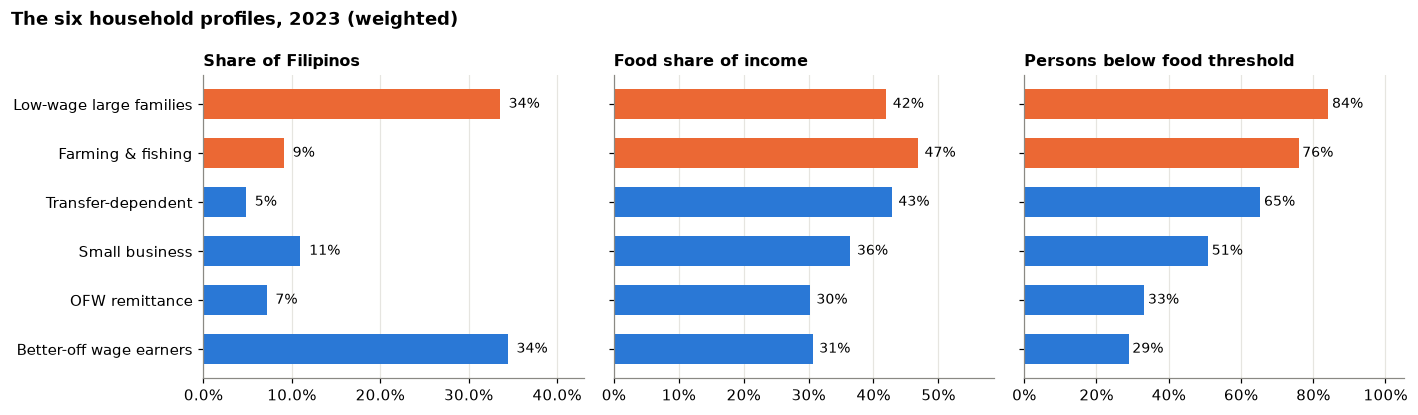

In [46]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
pp = prof.iloc[::-1]
for a, (c, t, fmt) in zip(ax, [("% of Filipinos", "Share of Filipinos", "{:.0%}"),
                              ("food_share_inc", "Food share of income", "{:.0%}"),
                              ("% persons below food threshold", "Persons below food threshold", "{:.0%}")]):
    a.barh(pp.index, pp[c], color=[PAL[1] if i in ORDER[:2] else PAL[0] for i in pp.index], height=.62)
    for yv, v in enumerate(pp[c]): a.text(v + .01, yv, fmt.format(v), va="center", fontsize=9)
    a.set_title(t, fontsize=10.5); a.xaxis.set_major_formatter(mtick.PercentFormatter(1)); a.grid(axis="y", visible=False)
    a.set_xlim(0, max(pp[c]) * 1.25)
fig.suptitle("The six household profiles, 2023 (weighted)", x=.01, ha="left", fontweight="semibold"); plt.tight_layout()

Largest profile share in selected regions:
  BARMM: Farming & fishing = 52% of households (national: 9%)
  NCR: Better-off wage earners = 76% of households (national: 37%)
  VIII Eastern Visayas: Transfer-dependent = 19% of households (national: 7%)
  V Bicol: Transfer-dependent = 15% of households (national: 7%)
  I Ilocos: OFW remittance = 18% of households (national: 9%)


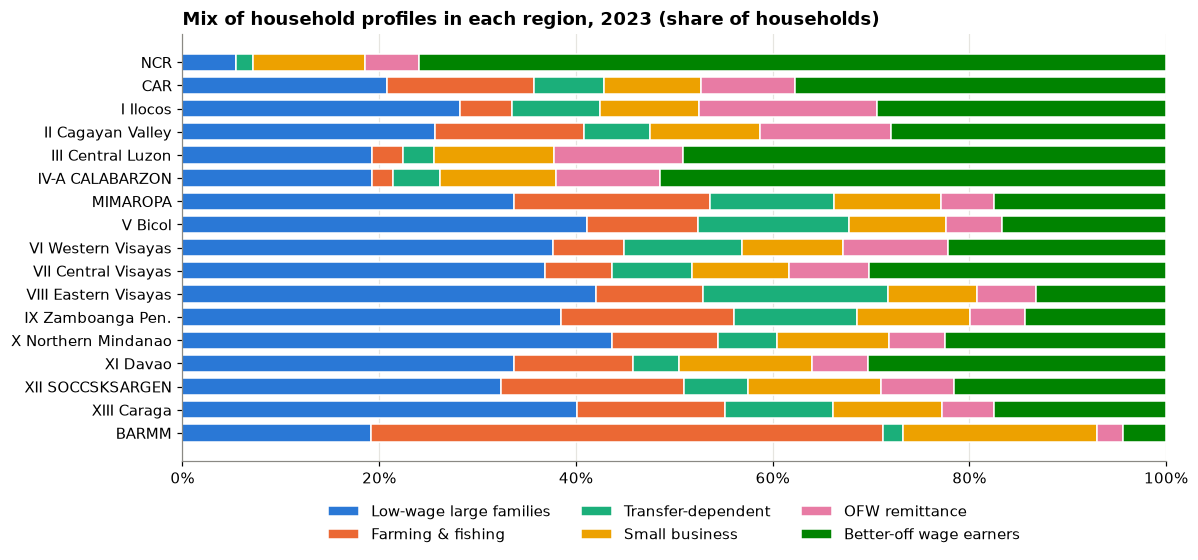

In [47]:
reg_mix = pd.crosstab(h.region, h.profile, values=h.rfact, aggfunc="sum", normalize="index")[ORDER]
fig, ax = plt.subplots(figsize=(11, 5.2))
left = np.zeros(len(reg_mix))
cols = {p: c for p, c in zip(ORDER, PAL)}
for p in ORDER:
    ax.barh(reg_mix.index.astype(str), reg_mix[p], left=left, color=cols[p], label=p, edgecolor="white", linewidth=1, height=.75)
    left += reg_mix[p].values
ax.invert_yaxis(); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.grid(axis="y", visible=False); ax.set_xlim(0, 1)
ax.set_title("Mix of household profiles in each region, 2023 (share of households)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(.5, -.07))
plt.tight_layout()
print("Largest profile share in selected regions:")
for r_, p_ in [("BARMM", "Farming & fishing"), ("NCR", "Better-off wage earners"), ("VIII Eastern Visayas", "Transfer-dependent"),
               ("V Bicol", "Transfer-dependent"), ("I Ilocos", "OFW remittance")]:
    print(f"  {r_}: {p_} = {reg_mix.loc[r_, p_]:.0%} of households (national: {(h.profile == p_).mul(h.rfact).sum() / h.rfact.sum():.0%})")

findfont: Failed to find font weight semibold, now using 700.


Variance explained by PC1, PC2: [0.242 0.14 ] | total 0.382


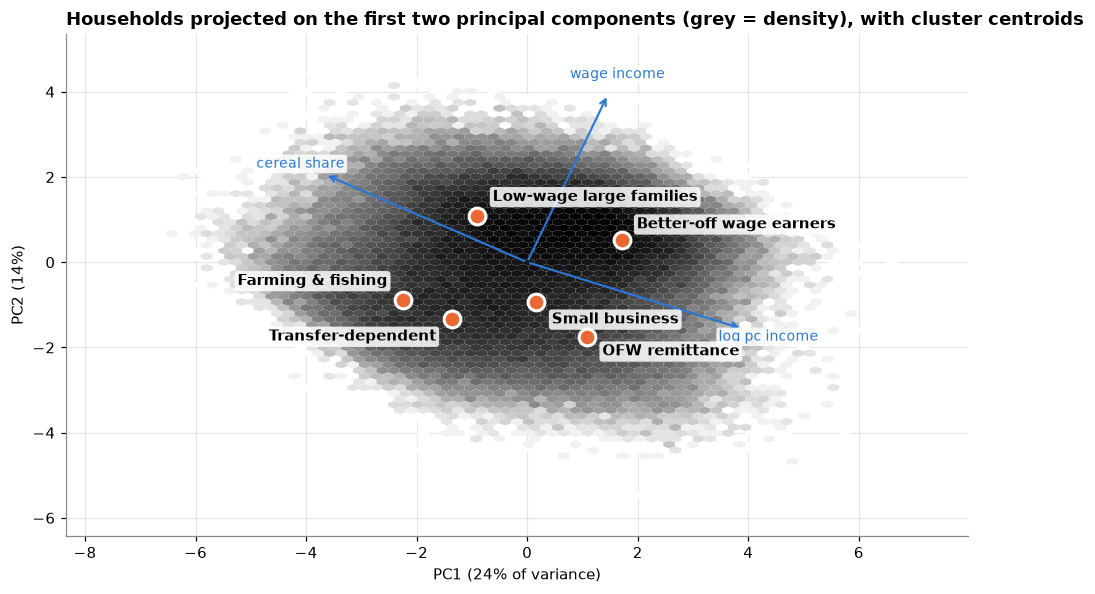

In [48]:
pca = PCA(n_components=2, random_state=0).fit(X)
P = pca.transform(X); C2 = pca.transform(km.cluster_centers_)
print("Variance explained by PC1, PC2:", pca.explained_variance_ratio_.round(3), "| total", pca.explained_variance_ratio_.sum().round(3))
load = pd.DataFrame(pca.components_.T, index=FEAT, columns=["PC1", "PC2"])
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.hexbin(P[:, 0], P[:, 1], gridsize=70, cmap="Greys", bins="log", mincnt=1, linewidths=0)
for f in ["log_pcinc", "sh_cereal", "inc_wages"]:                      # the three strongest loadings, as direction arrows
    tip_ = load.loc[f] / np.linalg.norm(load.loc[f]) * 4.2
    ax.annotate("", xy=tip_, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=PAL[0], lw=1.4))
    ax.text(*(tip_ * 1.12), labels[f], color=PAL[0], fontsize=9, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=.85))
OFF = {"Low-wage large families": (10, 10, "left"), "Better-off wage earners": (10, 8, "left"), "Small business": (10, -14, "left"),
       "OFW remittance": (10, -12, "left"), "Farming & fishing": (-10, 10, "right"), "Transfer-dependent": (-10, -14, "right")}
for i in range(K):
    ax.scatter(*C2[i], s=120, color=PAL[1], edgecolor="white", linewidth=2, zorder=3)
    dx, dy, ha = OFF[names[i]]
    ax.annotate(names[i], C2[i], xytext=(dx, dy), textcoords="offset points", fontsize=9.5, fontweight="semibold", ha=ha,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=.85))
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Households projected on the first two principal components (grey = density), with cluster centroids")
plt.tight_layout()

## 4.5 How stable are the clusters?
A clustering is only worth interpreting if it does not depend on the random start. We refit with five other seeds, and on two random halves of the data, and compare the labels with the **Adjusted Rand Index (ARI)**. An ARI of 1 means identical groupings and 0 means agreement no better than chance.

In [49]:
ari_seed = [adjusted_rand_score(km.labels_, KMeans(K, n_init=10, random_state=s).fit_predict(X)) for s in [1, 2, 3, 4, 5]]
half = rng.permutation(len(X))[: len(X) // 2]
km_half = KMeans(K, n_init=10, random_state=0).fit(X[half])
ari_half = adjusted_rand_score(km.labels_, km_half.predict(X))
print("ARI vs other random seeds:", np.round(ari_seed, 3))
print(f"ARI, model fitted on a random half then applied to all households: {ari_half:.3f}")

ARI vs other random seeds: [0.995 0.998 0.996 0.998 0.995]
ARI, model fitted on a random half then applied to all households: 0.991


**What the clusters show.** The six profiles, in order of how many members fall below the food threshold:

| Profile | Share of Filipinos | Defining traits | Food share of income | Below food threshold |
|---|---|---|---|---|
| **Low-wage large families** | 34% | wage-earning (69% of income), largest families (5.1 members), 64% rural, PHP 42k per capita | 42% | **84%** |
| **Farming & fishing** | 9% | 58% of income from farming or fishing, 82% rural, the lowest income (PHP 36k per capita) | **47%** (highest) | 76% |
| **Transfer-dependent** | 5% | small households (2.8 members), 41% of income from domestic cash transfers | 43% | 65% |
| **Small business** | 11% | 61% of income from own business | 36% | 51% |
| **OFW remittance** | 7% | 52% of income from abroad, PHP 98k per capita | 30% | 33% |
| **Better-off wage earners** | 34% | 75% wages, 80% urban, the highest income (PHP 101k), most eating out (17%) | 31% | 29% |

**Main points:**
- **Livelihood, not just income, separates the groups.** The low-wage, farming and transfer-dependent profiles all put **34–39%** of their home food budget into cereals and only **33–36%** into animal-source foods. The OFW and better-off wage profiles spend about **25–26%** on cereals and **43–44%** on animal foods.
- **The two most exposed groups cover 43% of Filipinos.** Low-wage large families and farming & fishing households together are about 43% of the population. In both, more than three in four people fall below the food threshold.
- **Farming and fishing households carry the heaviest burden.** They spend 47% of income on food, the most of any group. Yet fewer of them fall below the threshold than low-wage large families. Their home-grown food is valued at farm-gate prices, and they have fewer mouths to feed per peso.
- **Each profile has a regional home:**
  - farming & fishing households make up **about half of BARMM's** households;
  - better-off wage earners make up about **three-quarters of NCR's**;
  - transfer-dependent households are most common in **Eastern Visayas and Bicol**;
  - OFW households are most common in **Ilocos**.
- **PCA view.** The first two principal components explain only 38% of the variation, so the clusters overlap in that view. Much of what separates them is the income-source dimension, which a 2D projection cannot fully show.
- **The clusters are very stable.** Refitting with five other random seeds gives ARI = **0.995–0.998**. A model fitted on half the data and applied to all households gives ARI = **0.991**. These are robust structures, not accidents of initialization.

These profiles are the "who" of the research question. T1 and T2 test whether the differences between them are statistically real.

---
# 5. Statistical Inference

We test five claims from the EDA and the clusters. Every test uses significance level **α = 0.05** (Bonferroni-adjusted where several tests are run together).

| # | Claim tested | Test |
|---|---|---|
| T1 | Food burden differs across the six household profiles | Kruskal–Wallis H (+ pairwise Mann–Whitney post-hoc) |
| T2 | Household profile is associated with urban/rural location and with region | Chi-square test of independence |
| T3 | At the *same* income level, rural households spend a larger share on cereals than urban ones | One-sided Mann–Whitney U, within each decile |
| T4 | Regions with more cereal-heavy budgets have higher poverty | Spearman rank correlation (n = 17) |
| T5 | Food spending fell further behind the food threshold between 2021 and 2023 | Paired test across 17 regions (paired t or Wilcoxon signed-rank) |

**Two things to keep in mind:**
- **Very large samples make tiny differences "significant".** With 163,000 households, even a trivial difference gives p < 0.001. So every test also reports an **effect size** (ε², Cramér's V, rank-biserial r, ρ) and is judged on that. As an extra check, the household-level tests are repeated on a random subsample of 2,000 households.
- **The tests treat households as a simple random sample.** FIES actually samples in clusters and strata, which makes true standard errors larger than these tests assume. That is another reason to rely on effect sizes and to read p-values close to 0.05 with caution.

## T1: Does food burden differ across household profiles?
- **H₀:** the distribution of food share of income is the same in all six profiles.
- **H₁:** at least one profile's distribution differs (tends to be higher or lower).

**Choosing the test.** One-way ANOVA would compare means. It assumes (1) independent observations, (2) normality within each group and (3) equal variances. We check (2) and (3) first.

In [50]:
from scipy import stats
groups_t1 = [h.loc[h.profile == p, "food_share_inc"].values for p in ORDER]
norm = pd.DataFrame({p: {"n": len(g), "skewness": stats.skew(g), "D'Agostino K² p-value": stats.normaltest(g).pvalue,
                         "Shapiro–Wilk p (n=500 sample)": stats.shapiro(rng.choice(g, 500, replace=False)).pvalue}
                     for p, g in zip(ORDER, groups_t1)}).T
lev = stats.levene(*groups_t1, center="median")
print(f"Levene (Brown–Forsythe) test of equal variances: W = {lev.statistic:.1f}, p = {lev.pvalue:.2e}")
norm

Levene (Brown–Forsythe) test of equal variances: W = 369.6, p = 0.00e+00


,n,skewness,D'Agostino K² p-value,Shapiro–Wilk p (n=500 sample)
Low-wage large families,"46,585.000",0.256,0.000,0.051
Farming & fishing,"19,790.000",0.153,0.000,0.021
Transfer-dependent,"13,577.000",0.245,0.000,0.010
Small business,"18,806.000",0.287,0.000,0.107
OFW remittance,"13,127.000",0.511,0.000,0.000
Better-off wage earners,"51,382.000",0.452,0.000,0.000


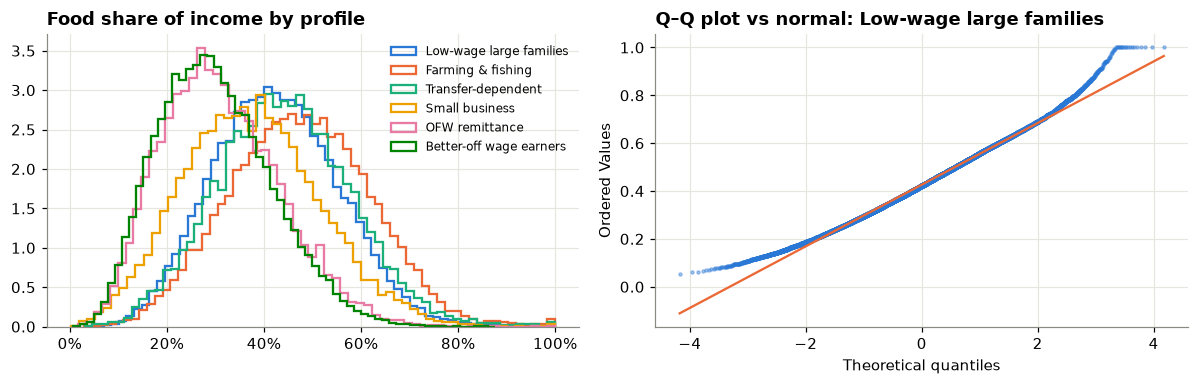

In [51]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for i, (p, g) in enumerate(zip(ORDER, groups_t1)):
    ax[0].hist(g, bins=60, histtype="step", lw=1.5, density=True, color=PAL[i], label=p)
ax[0].set_title("Food share of income by profile"); ax[0].legend(fontsize=8); ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1))
stats.probplot(groups_t1[0], dist="norm", plot=ax[1]); ax[1].get_lines()[0].set(markersize=2, color=PAL[0], alpha=.4)
ax[1].get_lines()[1].set(color=PAL[1]); ax[1].set_title(f"Q–Q plot vs normal: {ORDER[0]}")
plt.tight_layout()

**Assumption check.**
- **Normality fails.** The D'Agostino K² test rejects it in all six groups. On small random samples of 500, Shapiro–Wilk still rejects it for four of the six. The histograms are right-skewed and bounded at 0 and 1, and the Q–Q plot bends away from the line at both tails.
- **Equal variances fail.** The Brown–Forsythe/Levene test rejects equal variances (p ≈ 0). This alone rules out classical ANOVA.

So we use ANOVA's non-parametric alternative.

**Kruskal–Wallis H test.** It ranks all observations together and tests whether the mean rank differs between groups. Its assumptions:
- independent observations (households are distinct);
- an ordinal or continuous outcome (a proportion qualifies);
- similarly shaped distributions, if the result is to be read as a difference in medians.

The histograms above have broadly similar shapes, so it is reasonable to describe the result in terms of medians. The effect size is $\varepsilon^2 = H / (n - 1)$; values around 0.01 are small, 0.06 medium and 0.14 or more large. Pairwise one-sided Mann–Whitney tests with a Bonferroni correction then show *which* profiles differ.

In [52]:
H, p_kw = stats.kruskal(*groups_t1)
n_all = sum(len(g) for g in groups_t1)
eps2 = H / (n_all - 1)
sub = h.sample(2000, random_state=11)
H_s, p_s = stats.kruskal(*[sub.loc[sub.profile == p, "food_share_inc"] for p in ORDER])
fmt_p = lambda p: "p < 1e-300 (below floating-point precision)" if p == 0 else f"p = {p:.3g}"
print(f"Kruskal–Wallis: H = {H:,.1f}, df = {K-1}, {fmt_p(p_kw)}, epsilon² = {eps2:.3f}")
print(f"Robustness, random subsample of 2,000 households: H = {H_s:.1f}, p = {p_s:.3g}")
print("Medians:", {p: round(float(np.median(g)), 3) for p, g in zip(ORDER, groups_t1)})

Kruskal–Wallis: H = 35,091.6, df = 5, p < 1e-300 (below floating-point precision), epsilon² = 0.215
Robustness, random subsample of 2,000 households: H = 482.8, p = 4.19e-102
Medians: {'Low-wage large families': 0.422, 'Farming & fishing': 0.474, 'Transfer-dependent': 0.439, 'Small business': 0.369, 'OFW remittance': 0.301, 'Better-off wage earners': 0.29}


In [53]:
from itertools import combinations
pairs = []
m = len(list(combinations(ORDER, 2)))
for a, b in combinations(ORDER, 2):
    ga, gb = h.loc[h.profile == a, "food_share_inc"], h.loc[h.profile == b, "food_share_inc"]
    u, p = stats.mannwhitneyu(ga, gb, alternative="two-sided")
    r_rb = 2 * u / (len(ga) * len(gb)) - 1        # rank-biserial correlation: P(a > b) - P(a < b)
    pairs.append({"profile A": a, "profile B": b, "median A": ga.median(), "median B": gb.median(), "rank-biserial r (A vs B)": r_rb,
                  "p (Bonferroni)": min(1, p * m)})
pairs = pd.DataFrame(pairs)
pairs["significant at 0.05"] = pairs["p (Bonferroni)"] < .05
pairs.sort_values("rank-biserial r (A vs B)", key=abs, ascending=False)

,profile A,profile B,median A,median B,rank-biserial r (A vs B),p (Bonferroni),significant at 0.05
8,Farming & fishing,Better-off wage earners,0.474,0.290,0.655,0.000,True
7,Farming & fishing,OFW remittance,0.474,0.301,0.613,0.000,True
11,Transfer-dependent,Better-off wage earners,0.439,0.290,0.571,0.000,True
4,Low-wage large families,Better-off wage earners,0.422,0.290,0.534,0.000,True
10,Transfer-dependent,OFW remittance,0.439,0.301,0.524,0.000,True
3,Low-wage large families,OFW remittance,0.422,0.301,0.484,0.000,True
6,Farming & fishing,Small business,0.474,0.369,0.387,0.000,True
13,Small business,Better-off wage earners,0.369,0.290,0.315,0.000,True
9,Transfer-dependent,Small business,0.439,0.369,0.274,0.000,True
12,Small business,OFW remittance,0.369,0.301,0.263,0.000,True


**Result and decision.**
- **The test is decisive.** Kruskal–Wallis gives **H = 35,092 (df = 5), p < 10⁻³⁰⁰**, with effect size **ε² = 0.215**, a large effect. It stays decisive on a random subsample of 2,000 households (p ≈ 10⁻¹⁰²), so the result is not an artefact of sample size. **We reject H₀: food burden differs across the household profiles.**
- **Median food share of income by profile:**

  | Profile | Median food share |
  |---|---|
  | Farming & fishing | 47.4% |
  | Transfer-dependent | 43.9% |
  | Low-wage large families | 42.2% |
  | Small business | 36.9% |
  | OFW remittance | 30.1% |
  | Better-off wage earners | 29.0% |

- **Post-hoc tests.** All 15 pairs differ after the Bonferroni correction, but the effect sizes separate meaningful gaps from trivial ones:
  - the largest gaps are farming & fishing vs better-off wage earners (rank-biserial **r = 0.66**) and vs OFW households (r = 0.61);
  - **OFW vs better-off wage earners (r = 0.05)** and **low-wage vs transfer-dependent (r = −0.07)** are statistically significant but practically negligible.

  The six profiles therefore sort into roughly **three burden tiers**: farming / transfer / low-wage at the top, small business in the middle, and OFW / better-off wage at the bottom.

## T2: Are household profiles associated with location?
- **H₀:** profile and location are independent (the profile mix is the same everywhere).
- **H₁:** they are associated.

**Chi-square test of independence.** It compares observed counts in a contingency table with the counts expected under independence: $\chi^2 = \sum (O - E)^2 / E$. Its assumptions:
- each household is counted in exactly one cell;
- observations are independent;
- **every expected count is at least 5** (checked below).

The effect size is **Cramér's V** $= \sqrt{\chi^2 / (n \cdot (\min(r, c) - 1))}$; about 0.1 is small, 0.3 medium and 0.5 large. We run it twice: profile × urban/rural (6 × 2) and profile × region (6 × 17).

In [54]:
def chi2_report(tab, label):
    chi2, p, dof, exp = stats.chi2_contingency(tab)
    n = tab.values.sum(); v = np.sqrt(chi2 / (n * (min(tab.shape) - 1)))
    print(f"{label}: chi² = {chi2:,.1f}, df = {dof}, {fmt_p(p)}, Cramér's V = {v:.3f}, "
          f"min expected count = {exp.min():,.1f} (assumption {'met' if exp.min() >= 5 else 'NOT met'})")
    return pd.DataFrame((tab.values - exp) / np.sqrt(exp), index=tab.index, columns=tab.columns)   # standardized residuals

tab_area = pd.crosstab(h.profile, h.area).loc[ORDER]
res_area = chi2_report(tab_area, "Profile x urban/rural")
tab_reg = pd.crosstab(h.profile, h.region).loc[ORDER]
res_reg = chi2_report(tab_reg, "Profile x region")
sub = h.sample(2000, random_state=12)
chi2_report(pd.crosstab(sub.profile, sub.area), "Robustness, 2,000-household subsample: profile x urban/rural");
pd.concat({"observed % rural": tab_area.div(tab_area.sum(axis=1), axis=0)["Rural"], "standardized residual (Rural)": res_area["Rural"]}, axis=1)

Profile x urban/rural: chi² = 34,314.9, df = 5, p < 1e-300 (below floating-point precision), Cramér's V = 0.458, min expected count = 6,243.4 (assumption met)
Profile x region: chi² = 54,301.5, df = 80, p < 1e-300 (below floating-point precision), Cramér's V = 0.258, min expected count = 489.4 (assumption met)
Robustness, 2,000-household subsample: profile x urban/rural: chi² = 411.2, df = 5, p = 1.13e-86, Cramér's V = 0.453, min expected count = 79.9 (assumption met)


,observed % rural,standardized residual (Rural)
profile,,
Low-wage large families,0.677,45.525
Farming & fishing,0.847,62.593
Transfer-dependent,0.777,40.667
Small business,0.400,-23.540
OFW remittance,0.540,2.439
Better-off wage earners,0.237,-90.090


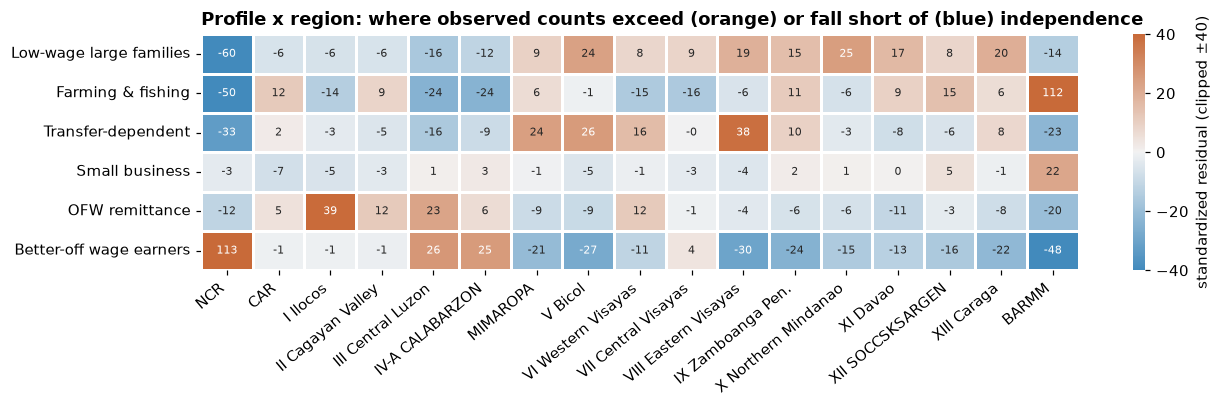

In [55]:
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(res_reg.clip(-40, 40), cmap=sns.diverging_palette(240, 28, s=80, l=55, as_cmap=True), center=0, annot=res_reg.round(0), fmt=".0f",
            annot_kws={"size": 7.5}, linewidths=.8, linecolor="white", cbar_kws={"label": "standardized residual (clipped ±40)"}, ax=ax)
ax.set_title("Profile x region: where observed counts exceed (orange) or fall short of (blue) independence"); ax.set_xlabel(""); ax.set_ylabel(""); ax.grid(False)
plt.xticks(rotation=40, ha="right"); plt.tight_layout()

**Result and decision.** Every expected count is far above 5 (minimum 6,243 for urban/rural, 489 for region), so the chi-square approximation is valid.
- **Profile × urban/rural:** χ² = 34,315, df = 5, p < 10⁻³⁰⁰, **Cramér's V = 0.46**, a strong association. It is unchanged on a 2,000-household subsample (V = 0.45). The standardized residuals show where it comes from:
  - farming & fishing (85% rural, residual **+63**), low-wage large families (+46) and transfer-dependent households (+41) are over-represented in rural areas;
  - better-off wage earners are strongly under-represented there (**−90**).
- **Profile × region:** χ² = 54,302, df = 80, p < 10⁻³⁰⁰, **V = 0.26**, a moderate association. The largest residuals:
  - **farming & fishing in BARMM (+112)**;
  - **better-off wage earners in NCR (+113)**;
  - OFW households in Ilocos (+39);
  - transfer-dependent households in Eastern Visayas (+38) and Bicol (+26).

**We reject H₀ in both tests.** Where a household lives and how it earns its living go together. This is why food burden shows up as a regional pattern in the EDA.

## T3: At the same income, do rural households spend more of their food budget on cereals?
EDA Q3 suggested a rural-urban gap in cereal share *within* every decile. Testing within deciles holds income roughly constant, so a difference cannot simply be because rural households are poorer.

- **H₀ (each decile):** the cereal share of rural households is not stochastically greater than that of urban households.
- **H₁ (one-sided):** rural households tend to have a higher cereal share.

**Choosing the test.** A two-sample t-test needs normality within groups. Cereal share is bounded and skewed (checked below), so we use the **Mann–Whitney U test**. Its assumptions are independent samples and an ordinal or continuous outcome; it makes no normality assumption. Ten tests are run, so the **Bonferroni** threshold is 0.05 / 10 = **0.005**. The effect size is the rank-biserial r, which equals P(rural > urban) − P(rural < urban).

In [56]:
print("Normality of cereal share (D'Agostino K², all 2023 households): p =", f"{stats.normaltest(h.sh_cereal).pvalue:.2e}",
      "| skewness =", round(stats.skew(h.sh_cereal), 3))
rows = []
for dcl in range(1, 11):
    z = h[h.decile == dcl]
    r_, u_ = z.loc[z.area == "Rural", "sh_cereal"], z.loc[z.area == "Urban", "sh_cereal"]
    U, p = stats.mannwhitneyu(r_, u_, alternative="greater")
    rows.append({"decile": dcl, "n rural": len(r_), "n urban": len(u_), "median rural": r_.median(), "median urban": u_.median(),
                 "difference (pp)": 100 * (r_.median() - u_.median()), "U": U, "p (one-sided)": p,
                 "rank-biserial r": 2 * U / (len(r_) * len(u_)) - 1})
t3 = pd.DataFrame(rows).set_index("decile")
t3["reject H0 at 0.005"] = t3["p (one-sided)"] < 0.005
t3

Normality of cereal share (D'Agostino K², all 2023 households): p = 0.00e+00 | skewness = 0.583


,n rural,n urban,median rural,median urban,difference (pp),U,p (one-sided),rank-biserial r,reject H0 at 0.005
decile,,,,,,,,,
1,10744,3259,0.439,0.428,1.101,"18,394,281.000",0.000,0.051,True
2,10915,4323,0.392,0.381,1.082,"25,157,330.000",0.000,0.066,True
3,10493,5269,0.365,0.352,1.306,"29,817,343.500",0.000,0.079,True
4,9669,5991,0.345,0.328,1.696,"32,108,795.000",0.000,0.109,True
5,8915,6820,0.330,0.310,2.032,"34,404,699.000",0.000,0.132,True
6,8011,7932,0.313,0.294,1.895,"35,565,450.000",0.000,0.119,True
7,7364,8557,0.294,0.279,1.433,"34,798,169.500",0.000,0.104,True
8,6813,9728,0.279,0.265,1.306,"36,108,646.000",0.000,0.090,True
9,6428,11188,0.261,0.251,1.010,"38,546,160.500",0.000,0.072,True


**Result and decision.**
- **The test rejects H₀ in all 10 deciles** (every p < 10⁻⁵, well under the Bonferroni threshold of 0.005). Even at the same income level, rural households put a larger share of their home food budget into cereals than urban households.
- **The effect is real but small.** The median gap is **0.8 to 2.0 percentage points**, and the rank-biserial r is **0.05 to 0.13**. The gap is largest in the middle deciles (decile 5: 33.0% vs 31.0%, r = 0.13) and smallest at the two extremes, where almost everyone (decile 1) or almost no one (decile 10) relies heavily on rice.

**How to read it.** Location matters independently of income, but modestly. Together with T1 and T2, this suggests livelihood (farming, transfers, low wages) is the larger driver, and rural location adds a smaller effect on top. Possible reasons for the rural effect include fewer affordable animal-source foods in rural markets and home-grown rice valued at low farm-gate prices.

## T4: Do regions with more cereal-heavy budgets have more poverty?
- **H₀:** ρ = 0, no monotonic association between a region's cereal share and its poverty incidence.
- **H₁ (one-sided):** ρ > 0, more cereal-heavy regions are poorer.

**Choosing the test.** There are only **n = 17 regions**. Pearson's r tests a *linear* relationship and needs both variables to be roughly normal. With so few points, a single extreme region can drive it. **Spearman's ρ** works on ranks: it only needs paired ordinal observations and tests any *monotonic* relationship. We check normality with Shapiro–Wilk (suitable for small n), report Pearson alongside, and use Spearman as the main test. The unit here is the **region**, with each region's figure computed using survey weights, so the large-n problem does not arise.

In [57]:
rg = q3[["cereal % of home food", "poverty incidence (families, %)", "animal-source % of home food"]].copy()
for c in rg.columns:
    print(f"Shapiro–Wilk, {c}: W = {stats.shapiro(rg[c]).statistic:.3f}, p = {stats.shapiro(rg[c]).pvalue:.3f}")
rho, p_rho = stats.spearmanr(rg["cereal % of home food"], rg["poverty incidence (families, %)"], alternative="greater")
r_p, p_p = stats.pearsonr(rg["cereal % of home food"], rg["poverty incidence (families, %)"], alternative="greater")
rho2, p_rho2 = stats.spearmanr(rg["animal-source % of home food"], rg["poverty incidence (families, %)"], alternative="less")
print(f"\nSpearman: cereal share vs poverty         rho = {rho:.3f}, one-sided p = {p_rho:.2e}")
print(f"Pearson (for reference):                   r   = {r_p:.3f}, one-sided p = {p_p:.2e}")
print(f"Spearman: animal-source share vs poverty  rho = {rho2:.3f}, one-sided p (H1: rho < 0) = {p_rho2:.2e}")

Shapiro–Wilk, cereal % of home food: W = 0.804, p = 0.002
Shapiro–Wilk, poverty incidence (families, %): W = 0.961, p = 0.650
Shapiro–Wilk, animal-source % of home food: W = 0.909, p = 0.097

Spearman: cereal share vs poverty         rho = 0.857, one-sided p = 5.52e-06
Pearson (for reference):                   r   = 0.877, one-sided p = 1.91e-06
Spearman: animal-source share vs poverty  rho = -0.901, one-sided p (H1: rho < 0) = 3.94e-07


**Result and decision.**
- **Spearman is the right choice here.** Shapiro–Wilk rejects normality for regional cereal share (W = 0.80, **p = 0.002**). The regions split into a low-cereal Luzon group and a high-cereal rest, so Pearson's normality requirement is not met.
- **The association is strong and decisive.** Spearman gives **ρ = 0.86, one-sided p = 5.5 × 10⁻⁶**. Pearson gives r = 0.88 for reference. **We reject H₀: regions where households spend more of their food budget on cereals have higher poverty incidence.**
- **The mirror image holds too.** The animal-source share is just as strongly and *negatively* associated with poverty: ρ = −0.90, p = 3.9 × 10⁻⁷.

**Caveat.** This is an *ecological* correlation across 17 regions. It shows that poor regions have cereal-heavy budgets. It does not show that eating more rice *causes* poverty, or that every household in a poor region eats this way. The household-level evidence for that comes from Q1 and T3.

## T5: Did food spending fall further behind the food threshold from 2021 to 2023?
For each region we compute the **ratio of average food spending per person to the regional food threshold**, in 2021 and in 2023. The same 17 regions are measured twice, so the samples are **paired**.

- **H₀:** the median (or mean) change in the ratio from 2021 to 2023 is 0.
- **H₁ (one-sided):** the ratio fell, so spending lost ground to the cost of a minimum nutritious diet.

**Choosing the test.** A paired t-test assumes the 17 *differences* are approximately normal. We check them with Shapiro–Wilk. If normality is rejected, we use the **Wilcoxon signed-rank test**, which only assumes the differences are symmetric around their median. Both results are reported.

In [58]:
def ratio(y):
    z = fies[fies.year == y]
    return z.groupby("region", observed=True).apply(lambda x: ((x.food * x.rfact).sum() / (x.fsize * x.rfact).sum()) / x.food_threshold.iloc[0])
t5 = pd.DataFrame({"ratio 2021": ratio(2021), "ratio 2023": ratio(2023)})
t5["change"] = t5["ratio 2023"] - t5["ratio 2021"]
sw = stats.shapiro(t5.change)
tt = stats.ttest_rel(t5["ratio 2023"], t5["ratio 2021"], alternative="less")
wx = stats.wilcoxon(t5["ratio 2023"], t5["ratio 2021"], alternative="less")
dz = t5.change.mean() / t5.change.std(ddof=1)
print(f"Shapiro–Wilk on the 17 differences: W = {sw.statistic:.3f}, p = {sw.pvalue:.3f}")
print(f"Paired t-test (one-sided):          t = {tt.statistic:.3f}, p = {tt.pvalue:.4f}, Cohen's d_z = {dz:.2f}")
print(f"Wilcoxon signed-rank (one-sided):   W = {wx.statistic:.1f}, p = {wx.pvalue:.4f}")
print(f"Regions where the ratio fell: {(t5.change < 0).sum()} of {len(t5)}; median change = {t5.change.median():+.3f}")
t5.sort_values("change")

Shapiro–Wilk on the 17 differences: W = 0.952, p = 0.483
Paired t-test (one-sided):          t = -1.665, p = 0.0577, Cohen's d_z = -0.40
Wilcoxon signed-rank (one-sided):   W = 46.0, p = 0.0797
Regions where the ratio fell: 11 of 17; median change = -0.037


,ratio 2021,ratio 2023,change
region,,,
IV-A CALABARZON,1.294,1.140,-0.154
VIII Eastern Visayas,1.085,0.940,-0.146
V Bicol,0.984,0.846,-0.139
VI Western Visayas,1.126,1.032,-0.094
XI Davao,0.982,0.907,-0.075
X Northern Mindanao,0.899,0.850,-0.049
MIMAROPA,0.999,0.954,-0.045
III Central Luzon,1.142,1.104,-0.039
II Cagayan Valley,1.053,1.016,-0.037


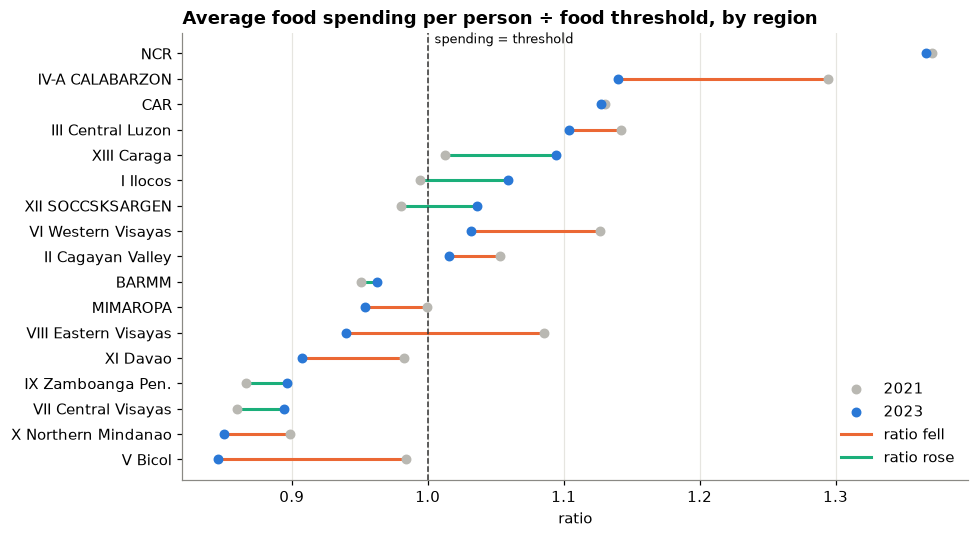

In [59]:
fig, ax = plt.subplots(figsize=(9, 5))
o = t5.sort_values("ratio 2023")
for i, (r, row) in enumerate(o.iterrows()):
    ax.plot([row["ratio 2021"], row["ratio 2023"]], [i, i], color=PAL[1] if row.change < 0 else PAL[2], lw=2)
ax.scatter(o["ratio 2021"], range(len(o)), color=MUTED, s=30, label="2021", zorder=3)
ax.scatter(o["ratio 2023"], range(len(o)), color=PAL[0], s=30, label="2023", zorder=3)
ax.axvline(1, color="#333", ls="--", lw=1); ax.text(1.005, len(o) - .6, "spending = threshold", fontsize=8.5)
ax.set_yticks(range(len(o))); ax.set_yticklabels(o.index); ax.grid(axis="y", visible=False)
ax.plot([], [], color=PAL[1], lw=2, label="ratio fell"); ax.plot([], [], color=PAL[2], lw=2, label="ratio rose")
ax.set_title("Average food spending per person ÷ food threshold, by region"); ax.set_xlabel("ratio"); ax.legend(loc="lower right")
plt.tight_layout()

**Result and decision.**
- **A paired t-test is the main test.** The 17 regional differences pass Shapiro–Wilk (W = 0.95, p = 0.48). The paired t-test gives **t = −1.67, one-sided p = 0.058**, Cohen's d_z = −0.40, a small-to-medium effect. The Wilcoxon signed-rank test agrees (**p = 0.080**).
- **We fail to reject H₀ at α = 0.05.** The ratio of food spending to the food threshold fell in **11 of 17 regions**, with a median change of −0.037. The sharpest falls were CALABARZON (−0.15), Eastern Visayas (−0.15) and Bicol (−0.14). But it *rose* in six regions, led by Caraga (+0.08), Ilocos and SOCCSKSARGEN.

**How to read it.** Nationally, the food threshold rose faster than food spending (+14.7% vs +11.4%, Q2). This test shows that the deterioration was **not uniform across regions**: some lost ground sharply, others gained. With only 17 regions the test has little power, so this is weak evidence of a general decline, not evidence of no change. For SAPAT, this argues for **region-specific** monitoring of affordability rather than a single national figure.

## 5.6 Summary of the tests

In [60]:
pd.DataFrame([
    ["T1", "Food burden differs across the six profiles", "Kruskal–Wallis H", "< 1e-300", f"ε² = {eps2:.3f}", "Reject H₀"],
    ["T2a", "Profile is associated with urban/rural", "Chi-square", "< 1e-300",
     f"V = {np.sqrt(stats.chi2_contingency(tab_area)[0] / tab_area.values.sum()):.3f}", "Reject H₀"],
    ["T2b", "Profile is associated with region", "Chi-square", "< 1e-300",
     f"V = {np.sqrt(stats.chi2_contingency(tab_reg)[0] / (tab_reg.values.sum() * (min(tab_reg.shape) - 1))):.3f}", "Reject H₀"],
    ["T3", "Rural cereal share > urban, same decile", "Mann–Whitney U ×10", f"max p = {t3['p (one-sided)'].max():.1e}",
     f"r = {t3['rank-biserial r'].min():.2f} to {t3['rank-biserial r'].max():.2f}",
     f"Reject H₀ in {t3['reject H0 at 0.005'].sum()}/10 deciles"],
    ["T4", "Cereal-heavy regions are poorer", "Spearman ρ", f"{p_rho:.1e}", f"ρ = {rho:.2f}", "Reject H₀"],
    ["T5", "Spending lost ground to the threshold", "Paired t / Wilcoxon", f"{tt.pvalue:.3f} / {wx.pvalue:.3f}", f"d_z = {dz:.2f}",
     "Reject H₀" if max(tt.pvalue, wx.pvalue) < .05 else ("Reject H₀ (t-test only)" if tt.pvalue < .05 else "Fail to reject H₀")],
], columns=["Test", "Claim", "Method", "p-value", "Effect size", "Decision (α = 0.05)"])

,Test,Claim,Method,p-value,Effect size,Decision (α = 0.05)
0,T1,Food burden differs across the six profiles,Kruskal–Wallis H,< 1e-300,ε² = 0.215,Reject H₀
1,T2a,Profile is associated with urban/rural,Chi-square,< 1e-300,V = 0.458,Reject H₀
2,T2b,Profile is associated with region,Chi-square,< 1e-300,V = 0.258,Reject H₀
3,T3,"Rural cereal share > urban, same decile",Mann–Whitney U ×10,max p = 5.7e-06,r = 0.05 to 0.13,Reject H₀ in 10/10 deciles
4,T4,Cereal-heavy regions are poorer,Spearman ρ,5.5e-06,ρ = 0.86,Reject H₀
5,T5,Spending lost ground to the threshold,Paired t / Wilcoxon,0.058 / 0.080,d_z = -0.40,Fail to reject H₀
